# Bank Marketing Campaign Optimization with Cost-Sensitive Machine Learning
## Cost-sensitive decisions under temporal distribution shift

This project evaluates term-deposit marketing decisions using 45,211 historical records from the UCI Bank Marketing dataset. The analysis combines predictive modeling, business costs and temporal evaluation to assess decision quality at the start of a recorded telephone call. Optimization refers to selecting the model and probability threshold under an explicit decision-cost objective.

**Project objective:** The objective is to quantify the later-period cost, predictive performance and operational stability of a model and probability threshold selected using business costs, and to compare this policy with default classification and simple business rules.

This notebook contains all analysis code, results and business interpretation in one file. It runs independently of any project-specific Python package. On first execution, the dataset is downloaded from UCI and verified against a fixed checksum. Charts and tables are embedded in the executed notebook for viewing on GitHub.

## Runtime and local outputs

Use Python 3.11 or 3.12 with the package versions below. Install them once in the active notebook environment if needed, then restart the kernel and run all cells. Dependencies are ordinary public Python libraries; no project source folder is required.

The first run needs internet access to retrieve UCI data. Later runs can use the checksum-verified cache. The notebook creates an `artifacts/` folder for its downloaded data, tables, figures and frozen policy. That folder is generated during execution and does not need to be uploaded to GitHub.

In [1]:
# Optional one-time setup; uncomment in a new notebook environment, then restart the kernel.
# %pip install numpy==2.3.5 pandas==2.2.3 scipy==1.16.3 scikit-learn==1.8.0 matplotlib==3.10.8 seaborn==0.13.2 joblib==1.5.2 threadpoolctl==3.8.0

## Business context and decision costs

The decision time is the **start of the recorded telephone call**. Client attributes, prior-campaign history, planned channel/date and the current attempt number are assumed available then. The completed call's duration is not.

We use the following **hypothetical loss matrix**:

| Actual subscription | Negative decision | Positive decision |
| --- | ---: | ---: |
| no | 0 | 5 |
| yes | 25 | 0 |

Thus $L=5FP+25FN$. A positive decision is an action-prioritization proxy; its FP cost is not a fee charged to every call. Costs are arbitrary study units, not euros, profit or observed bank spending. The primary policy has no capacity constraint. A capacity-constrained alternative is examined separately.

A useful policy should beat operational alternatives on a later period. Improving accuracy, AP or F1 alone does not establish that. Historical outcomes among contacted customers do not identify the incremental effect of contacting them.

## Protocol fixed before final evaluation

1. Preserve the original order of `bank-full.csv`; use a 60/20/20 train/validation/test split.
2. Fit all learned preprocessing and estimators on training only.
3. Compare eight predeclared models, then search each model's full validation threshold set.
4. Select minimum validation loss, with explicit tie rules. Retain the original training-fitted estimator.
5. Keep cost sensitivity, capacity budgets and explanatory development diagnostics on validation or earlier rows.
6. Save the model and full-precision threshold **before evaluating final-period labels**.
7. Compare the frozen policy against 0.5, always-no, always-yes and a prior-success rule. Holdout diagnostics never change it.

The single validation period serves both model and threshold selection, so its optimum is optimistic. The final holdout is one subsequent period, not repeated independent evidence. This published holdout is now known; future model development needs fresh evaluation data.

In [2]:
from pathlib import Path
from types import SimpleNamespace
import os
import io
import gzip
import hashlib
import json
import platform
import importlib.metadata
import ssl
import shutil
import subprocess
import urllib.request
import urllib.error
import zipfile

os.environ.setdefault('LOKY_MAX_CPU_COUNT', '2')
import numpy as np
import pandas as pd
import joblib
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, Image
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score, precision_recall_curve
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits

pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 6)
RUN_DIR = Path.cwd() / 'artifacts'
print('Run outputs and data cache: artifacts/ (created automatically)')
print('Python:', platform.python_version())
print('Positive target: yes; decision rule: probability >= threshold')

Matplotlib is building the font cache; this may take a moment.


Run outputs and data cache: artifacts/ (created automatically)
Python: 3.11.8
Positive target: yes; decision rule: probability >= threshold


## Dataset identity, quality and feature availability

Use **45,211 records and 16 original input variables** from the older `bank-full.csv`, not the newer 41,188-row variant. The loader validates the decompressed SHA-256, shape, schema and labels before analysis. The checksum identifies the original CSV verified against the official UCI download. UCI documents the file as date-ordered; a full timestamp and customer ID are absent.

We inspect data quality on training rows first. Identical rows remain: without IDs, equality is not enough to infer duplicate customers. We preserve the source order.

`pdays=-1` means no earlier campaign contact. We create a `previously_contacted` indicator, turn the unavailable interval into a missing numeric value and learn its valid-value median on training. Categorical `unknown` is retained as a level, not silently converted into an ordinal code. All numeric fields are imputed and standardized, and categories are one-hot encoded with unseen-level handling.

In [3]:
DATA_URL = 'https://archive.ics.uci.edu/static/public/222/bank+marketing.zip'
CSV_SHA256 = 'd1513ec63b385506f7cfce9f2c5caa9fe99e7ba4e8c3fa264b3aaf0f849ed32d'
CATEGORICAL = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
NUMERIC = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
INPUTS = ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']


def digest(content):
    return hashlib.sha256(content).hexdigest()


def load_data(root):
    """Download the exact older dataset on first run; verify cached bytes thereafter."""
    path = root / 'data/raw/bank-full.csv.gz'
    if not path.exists():
        print('Downloading Bank Marketing from UCI...')
        request = urllib.request.Request(DATA_URL, headers={'User-Agent': 'bank-marketing-case-study/1.0'})
        try:
            with urllib.request.urlopen(request, timeout=120) as response:
                payload = response.read()
        except urllib.error.URLError as error:
            # Some macOS Python installs lack system-root integration. Use the OS's
            # normal, certificate-verified curl transport when available.
            if not isinstance(error.reason, ssl.SSLCertVerificationError) or not shutil.which('curl'):
                raise RuntimeError('UCI download failed. Check network access and retry.') from error
            payload = subprocess.run(
                ['curl', '--fail', '--location', '--silent', '--show-error', '--max-time', '120', DATA_URL],
                capture_output=True, check=True).stdout
        with zipfile.ZipFile(io.BytesIO(payload)) as outer:
            with zipfile.ZipFile(io.BytesIO(outer.read('bank.zip'))) as inner:
                csv = inner.read('bank-full.csv')
        if digest(csv) != CSV_SHA256:
            raise ValueError('Downloaded dataset checksum mismatch; refusing a different CSV.')
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(gzip.compress(csv, mtime=0))
    csv = gzip.decompress(path.read_bytes())
    if digest(csv) != CSV_SHA256:
        raise ValueError('Cached CSV checksum mismatch. Remove the cache and rerun.')
    frame = pd.read_csv(io.BytesIO(csv), sep=';')
    if frame.shape != (45211, 17) or set(frame) != set(INPUTS + ['duration', 'y']):
        raise ValueError('Expected bank-full.csv with 45,211 rows and 17 columns.')
    if not set(frame.y.unique()) <= {'yes', 'no'} or frame.isna().any().any():
        raise ValueError('Unexpected labels or missing raw cells.')
    manifest = dict(dataset='UCI Bank Marketing: bank-full.csv', rows=45211, raw_columns=17,
                    csv_sha256=CSV_SHA256, source_url=DATA_URL, doi='10.24432/C5K306',
                    license='CC BY 4.0', order='Original UCI chronological file order')
    (root/'data/manifest.json').write_text(json.dumps(manifest, indent=2)+'\n')
    return frame


def ordered_splits(n):
    a, b = int(.6*n), int(.8*n)
    return slice(0, a), slice(a, b), slice(b, n)

### Reusable decision calculations

The following functions compute binary metrics and enumerate every distinct validation-score decision. Their definitions are included here so the notebook can be executed without separate source files.

In [4]:
def validate(y, scores):
    y, scores = np.asarray(y), np.asarray(scores, dtype=float)
    if y.ndim != 1 or scores.ndim != 1 or len(y) != len(scores) or not len(y):
        raise ValueError("Labels and scores must be nonempty, equal-length vectors")
    if not np.isin(y, [0, 1]).all() or not np.isfinite(scores).all() or ((scores < 0) | (scores > 1)).any():
        raise ValueError("Require binary labels and finite scores in [0, 1]")
    return y.astype(int), scores


def decision_metrics(y, predictions, fp_cost=5., fn_cost=25.):
    y, predictions = validate(y, predictions)
    if not np.isin(predictions, [0, 1]).all():
        raise ValueError('Predictions must be binary labels')
    if not np.isfinite([fp_cost, fn_cost]).all() or fp_cost < 0 or fn_cost < 0:
        raise ValueError('Costs must be finite and nonnegative')
    p = predictions.astype(bool)
    tp, fp = int(np.sum(p & (y == 1))), int(np.sum(p & (y == 0)))
    fn, tn = int(np.sum(~p & (y == 1))), int(np.sum(~p & (y == 0)))
    divide = lambda a, b: a / b if b else 0.
    cost = fp_cost * fp + fn_cost * fn
    return dict(TN=tn, FP=fp, FN=fn, TP=tp, precision=divide(tp, tp+fp),
                recall=divide(tp, tp+fn), f1=divide(2*tp, 2*tp+fp+fn),
                accuracy=(tp+tn)/len(y), action_rate=float(p.mean()),
                cost=cost, cost_per_1000=cost*1000/len(y))


def score_metrics(y, scores, threshold=.5, fp_cost=5., fn_cost=25.):
    y, scores = validate(y, scores)
    if np.isnan(threshold):
        raise ValueError("Threshold cannot be NaN")
    result = decision_metrics(y, scores >= threshold, fp_cost, fn_cost)
    result.update(average_precision=average_precision_score(y, scores) if y.sum() else 0.,
                  roc_auc=roc_auc_score(y, scores) if len(np.unique(y)) == 2 else np.nan,
                  brier=brier_score_loss(y, scores))
    return result


def threshold_table(y, scores, fp_cost=5., fn_cost=25.):
    """O(n log n), including 0, every unique score, and +inf; use p >= t."""
    y, scores = validate(y, scores)
    if not np.isfinite([fp_cost, fn_cost]).all() or fp_cost < 0 or fn_cost < 0:
        raise ValueError("Costs must be finite and nonnegative")
    order = np.argsort(scores, kind="stable")
    ordered = scores[order]
    thresholds = np.unique(np.r_[0., ordered, np.inf])
    left = np.searchsorted(ordered, thresholds, side="left")
    positives = np.r_[0, np.cumsum(y[order])]
    fn = positives[left]
    tp = positives[-1] - fn
    fp = len(y) - left - tp
    tn = left - fn
    divide = lambda a, b: np.divide(a, b, out=np.zeros(len(a), dtype=float), where=b != 0)
    cost = fp_cost*fp + fn_cost*fn
    return pd.DataFrame(dict(threshold=thresholds, TN=tn, FP=fp, FN=fn, TP=tp,
                             precision=divide(tp, tp+fp), recall=divide(tp, tp+fn),
                             f1=divide(2*tp, 2*tp+fp+fn), action_rate=(tp+fp)/len(y),
                             cost=cost, cost_per_1000=cost*1000/len(y)))


def optimum(table, objective="cost"):
    """Tables ascend by threshold; exact objective ties prefer higher threshold."""
    target = table[objective].min() if objective == "cost" else table[objective].max()
    return table.loc[table[objective] == target].iloc[-1]


def top_capacity(scores, fraction):
    """Budget floor(fraction*n), with ties resolved by original row position."""
    scores = np.asarray(scores)
    if not 0 <= fraction <= 1:
        raise ValueError("Capacity fraction must lie in [0, 1]")
    order = np.argsort(-scores, kind="stable")
    decisions = np.zeros(len(scores), dtype=int)
    decisions[order[:int(fraction*len(scores))]] = 1
    return decisions


def paired_block_bootstrap(y, scores, threshold, repeats=1000, block_size=200, seed=42):
    """Circular moving-block percentile CI for frozen minus 0.5 cost / 1,000."""
    y, scores = validate(y, scores)
    loss = lambda p: 5*((p == 1) & (y == 0)) + 25*((p == 0) & (y == 1))
    difference = loss(scores >= threshold) - loss(scores >= .5)
    rng = np.random.default_rng(seed)
    n = len(y)
    samples = np.empty(repeats)
    for i in range(repeats):
        starts = rng.integers(0, n, size=int(np.ceil(n/block_size)))
        indices = ((starts[:, None] + np.arange(block_size)) % n).ravel()[:n]
        samples[i] = 1000*difference[indices].mean()
    return dict(delta_per_1000=float(1000*difference.mean()),
                lower_95=float(np.quantile(samples, .025)), upper_95=float(np.quantile(samples, .975)),
                repeats=repeats, block_size=block_size, seed=seed)

In [5]:
# Independent checks of threshold counting, endpoints and tie handling.
for seed in range(12):
    rng = np.random.default_rng(seed)
    labels = rng.integers(0, 2, 87)
    scores = rng.choice([0., .05, .2, .5, .8, 1.], size=len(labels))
    sweep = threshold_table(labels, scores, fp_cost=3, fn_cost=17)
    for row in sweep.itertuples():
        pred = scores >= row.threshold
        fp = np.sum(pred & (labels == 0))
        fn = np.sum(~pred & (labels == 1))
        tp = np.sum(pred & (labels == 1))
        tn = np.sum(~pred & (labels == 0))
        assert (row.TN, row.FP, row.FN, row.TP) == (tn, fp, fn, tp)
        assert row.cost == 3*fp + 17*fn
    tied = sweep[sweep.cost == sweep.cost.min()]
    assert optimum(sweep).threshold == tied.threshold.max()
assert np.isposinf(optimum(threshold_table([0, 1], [.2, .8], 0, 0)).threshold)
np.testing.assert_array_equal(top_capacity([.8, .8, .8, .2], .5), [1, 1, 0, 0])
print('Independent threshold and capacity checks passed.')

Independent threshold and capacity checks passed.


In [6]:
def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (tuple, list, np.ndarray)):
        return [json_safe(v) for v in value]
    if isinstance(value, (np.integer, np.floating)):
        value = value.item()
    if isinstance(value, float) and not np.isfinite(value):
        return "infinity" if value > 0 else ("-infinity" if value < 0 else None)
    return value


def save_json(path, data):
    path.write_text(json.dumps(json_safe(data), indent=2, allow_nan=False) + "\n")


def save_table(study, name, frame):
    frame.to_csv(study.tables / f"{name}.csv", index=False, float_format="%.17g")
    return frame


def baselines(X, y):
    return pd.DataFrame([dict(policy=name, **decision_metrics(y, pred)) for name, pred in [
        ("Always no", np.zeros(len(y))), ("Always yes", np.ones(len(y))),
        ("Previous success rule", X.poutcome.eq("success").to_numpy(int)),
    ]])


def initialize_study(root):
    study = SimpleNamespace()
    study.root = Path(root).resolve()
    study.report = study.root / "reports"
    study.tables = study.report / "tables"
    study.figures = study.report / "figures"
    for p in (study.tables, study.figures, study.root / "models"):
        p.mkdir(parents=True, exist_ok=True)
    study.raw = load_data(study.root)
    study.tr, study.va, study.te = ordered_splits(len(study.raw))
    study.X_train = study.raw.iloc[study.tr].drop(columns="y")
    study.X_val = study.raw.iloc[study.va].drop(columns="y")
    study.y_train = study.raw.iloc[study.tr].y.eq("yes").to_numpy(int)
    study.y_val = study.raw.iloc[study.va].y.eq("yes").to_numpy(int)
    # Test labels are intentionally not materialized until evaluate_test().
    study.models = candidates()
    study.scores = {}
    study.sweeps = {}
    study.selected_name = None
    return study


def data_audit(study):
    train = study.raw.iloc[study.tr]
    audit = pd.DataFrame({"column": train.columns, "dtype": train.dtypes.astype(str).to_numpy(),
                          "missing_train": train.isna().sum().to_numpy(),
                          "distinct_train": train.nunique().to_numpy()})
    audit["unknown_train"] = [int(train[c].eq("unknown").sum()) for c in train]
    save_table(study, "data_audit_train", audit)
    split = pd.DataFrame([
        dict(partition="train", start=0, end_exclusive=study.tr.stop, rows=len(train), positive_rate=study.y_train.mean()),
        dict(partition="validation", start=study.va.start, end_exclusive=study.va.stop, rows=len(study.y_val), positive_rate=study.y_val.mean()),
    ])
    save_table(study, "development_splits", split)
    study.audit = dict(train_exact_duplicate_rows=int(train.duplicated().sum()),
                      train_no_previous_contact=int(train.pdays.eq(-1).sum()),
                      train_valid_pdays_median=float(train.loc[train.pdays != -1, "pdays"].median()))
    study.validation_baselines = save_table(study, "validation_baselines", baselines(study.X_val, study.y_val))
    return split

### Input transformation and candidate definitions

The definitions below keep feature handling and model construction inside this notebook. Models are fitted only in the later comparison step.

In [7]:
class BankFeatures(TransformerMixin, BaseEstimator):
    """Whitelist available inputs and represent the no-previous-contact sentinel."""
    def __init__(self, include_duration=False):
        self.include_duration = include_duration

    def fit(self, X, y=None):
        self.transform(X)
        self.feature_names_in_ = np.asarray(INPUTS + (["duration"] if self.include_duration else []))
        self.n_features_in_ = len(self.feature_names_in_)
        return self

    def transform(self, X):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Use a pandas DataFrame with named raw columns")
        required = INPUTS + (["duration"] if self.include_duration else [])
        missing = set(required) - set(X)
        if missing:
            raise ValueError(f"Missing raw input columns: {sorted(missing)}")
        result = X.loc[:, required].copy()
        for col in NUMERIC + (["duration"] if self.include_duration else []):
            result[col] = pd.to_numeric(result[col], errors="raise")
        result["previously_contacted"] = (result.pdays != -1).astype(int)
        result["pdays"] = result.pdays.replace(-1, np.nan)
        return result


def make_pipeline(estimator, include_duration=False):
    numerical = NUMERIC + (["duration"] if include_duration else []) + ["previously_contacted"]
    preprocess = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scaler", StandardScaler()),
        ]), numerical),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ])
    return Pipeline([("features", BankFeatures(include_duration)), ("preprocess", preprocess), ("model", estimator)])


def candidates():
    """Stable model order is the declared tie-break rule."""
    result = {}
    for c in (.1, 1, 10):
        result[f"Logistic_C{c:g}"] = make_pipeline(LogisticRegression(
            C=c, solver="lbfgs", max_iter=5000, class_weight=None, random_state=42))
    for depth in (3, 6, 12):
        result[f"Tree_depth{depth}"] = make_pipeline(DecisionTreeClassifier(
            max_depth=depth, criterion="gini", class_weight=None, random_state=42))
    # Predeclared additional families; no grid expansion after test evaluation.
    result["RandomForest"] = make_pipeline(RandomForestClassifier(
        n_estimators=200, max_depth=10, min_samples_leaf=20,
        max_features=.7, n_jobs=2, random_state=42))
    result["HistGradientBoosting"] = make_pipeline(HistGradientBoostingClassifier(
        max_iter=200, learning_rate=.05, max_leaf_nodes=15,
        l2_regularization=1., early_stopping=False, random_state=42))
    return result

In [8]:
study = initialize_study(RUN_DIR)
print("Verified data shape:", study.raw.shape)
display(data_audit(study))
display(pd.read_csv(study.tables/'data_audit_train.csv'))
display(pd.Series(study.audit, name='training_audit').to_frame())
display(study.validation_baselines[['policy','accuracy','precision','recall','f1','action_rate','cost_per_1000']])
display(pd.Series(json.loads((RUN_DIR/'data/manifest.json').read_text()), name='dataset').to_frame())

Verified data shape: (45211, 17)


,partition,start,end_exclusive,rows,positive_rate
0,train,0,27126,27126,0.050394
1,validation,27126,36168,9042,0.117894


,column,dtype,missing_train,distinct_train,unknown_train
0,age,int64,0,42,0
1,job,object,0,12,193
2,marital,object,0,3,0
3,education,object,0,4,1089
4,default,object,0,2,0
5,balance,int64,0,6053,0
6,housing,object,0,2,0
7,loan,object,0,2,0
8,contact,object,0,3,12761
9,day,int64,0,31,0


,training_audit
train_exact_duplicate_rows,0.0
train_no_previous_contact,26359.0
train_valid_pdays_median,164.0


,policy,accuracy,precision,recall,f1,action_rate,cost_per_1000
0,Always no,0.882106,0.000000,0.000000,0.000000,0.000000,2947.356779
1,Always yes,0.117894,0.117894,1.000000,0.210922,1.000000,4410.528644
2,Previous success rule,0.878345,0.401163,0.064728,0.111470,0.019022,2813.536828


,dataset
dataset,UCI Bank Marketing: bank-full.csv
rows,45211
raw_columns,17
csv_sha256,d1513ec63b385506f7cfce9f2c5caa9fe99e7ba4e8c3fa...
source_url,https://archive.ics.uci.edu/static/public/222/...
doi,10.24432/C5K306
license,CC BY 4.0
order,Original UCI chronological file order


The boundaries are zero-based and end-exclusive: `[0, 27126)` for training, `[27126, 36168)` for validation and `[36168, 45211)` for the final holdout. The training-majority class is `no`. Its high validation accuracy is achieved with zero positive recall and F1.

**Availability assumptions:** `campaign` is the current attempt number including this call. `poutcome` is a prior campaign result, not the current label. Channel, day and month are allowed because the planned details are assumed known at call start. This must be checked against an actual data feed before any deployment. `duration` and `y` are blocked by the raw-input feature whitelist.

## Candidate pipelines and diagnostic ranking

Each model receives the same preprocessing convention inside its own scikit-learn `Pipeline`:

`raw named columns → available-feature whitelist + prior-contact indicator → training-fitted imputation/scaling + one-hot encoding → classifier`

| Family | Predeclared settings |
| --- | --- |
| Logistic Regression | C in {0.1, 1, 10}, lbfgs, max_iter=5000, no class weights |
| Decision Tree | max_depth in {3, 6, 12}, Gini, no class weights |
| Random Forest | 200 trees, depth 10, minimum leaf 20, max_features=0.7 |
| Histogram Gradient Boosting | 200 iterations, learning rate 0.05, 15 leaves, L2=1, early_stopping=False |

All random states are 42 where relevant. Other settings are recorded from the installed estimators. Trees do not require numerical scaling; keeping it preserves a consistent preprocessing convention across candidates. Additional model families were declared before final evaluation and are not guaranteed to improve the result.

AP measures the continuous precision-recall ranking. F1 at 0.5 measures one thresholded decision. Neither alone is the primary selection objective.

In [9]:
def fit_and_select(study):
    rows, minima = [], []
    with threadpool_limits(limits=2):
        for name, pipeline in study.models.items():
            pipeline.fit(study.X_train, study.y_train)
            p = pipeline.predict_proba(study.X_val)[:, 1]
            study.scores[name] = p
            study.sweeps[name] = threshold_table(study.y_val, p)
            rows.append(dict(model=name, threshold=.5, **score_metrics(study.y_val, p)))
            minima.append(dict(model=name, **optimum(study.sweeps[name]).to_dict()))
    study.validation_models = save_table(study, "validation_models_at_05", pd.DataFrame(rows))
    study.minimum_costs = save_table(study, "validation_minimum_costs", pd.DataFrame(minima))
    study.selected_name = study.minimum_costs.loc[study.minimum_costs.cost.idxmin(), "model"]
    study.selected = study.models[study.selected_name]
    study.threshold = float(optimum(study.sweeps[study.selected_name]).threshold)
    study.f1_threshold = float(optimum(study.sweeps[study.selected_name], "f1").threshold)
    p = study.scores[study.selected_name]
    study.validation_policies = save_table(study, "validation_policy_comparison", pd.DataFrame([
        dict(policy=label, threshold=t, **score_metrics(study.y_val, p, t))
        for label, t in [("Default 0.5", .5), ("Frozen cost policy", study.threshold),
                         ("F1 optimum", study.f1_threshold), ("Calibrated-cost formula", 5/30)]
    ]))
    save_table(study, "selected_validation_thresholds", study.sweeps[study.selected_name])
    for name, sweep in study.sweeps.items():
        save_table(study, f"thresholds_{name}", sweep)
    settings = {name: m.named_steps["model"].get_params(deep=False) for name, m in study.models.items()}
    save_json(study.report / "model_settings.json", settings)
    encoder = study.selected.named_steps["preprocess"].named_transformers_["categorical"]
    study.unseen = save_table(study, "unseen_validation_categories", pd.DataFrame([
        dict(feature=c, unseen_values="|".join(sorted(set(study.X_val[c]) - set(levels))),
             unseen_rows=int((~study.X_val[c].isin(levels)).sum()))
        for c, levels in zip(encoder.feature_names_in_, encoder.categories_)
    ]))
    return study.minimum_costs

In [10]:
display(fit_and_select(study))
metrics = ['model','precision','recall','f1','accuracy','average_precision','roc_auc','brier']
display(study.validation_models[metrics])
display(study.validation_models[['model','f1','accuracy','average_precision']]
        .set_index('model').rank(ascending=False, method='min'))
settings = json.loads((study.report/'model_settings.json').read_text())
compact_keys = ['C','max_depth','min_samples_leaf','n_estimators','max_iter','learning_rate','max_leaf_nodes']
display(pd.DataFrame([{'model': name, **{key: value for key, value in params.items() if key in compact_keys}}
                      for name, params in settings.items()]))
print('Complete estimator defaults saved under artifacts/reports/.')

,model,threshold,TN,FP,FN,TP,precision,recall,f1,action_rate,cost,cost_per_1000
0,Logistic_C0.1,0.096577,6687.0,1289.0,756.0,310.0,0.193871,0.290807,0.232645,0.176841,25345.0,2803.030303
1,Logistic_C1,0.118219,6613.0,1363.0,751.0,315.0,0.187723,0.295497,0.229592,0.185578,25590.0,2830.126078
2,Logistic_C10,0.116255,6458.0,1518.0,725.0,341.0,0.183432,0.319887,0.233162,0.205596,25715.0,2843.950453
3,Tree_depth3,inf,7976.0,0.0,1066.0,0.0,0.000000,0.000000,0.000000,0.000000,26650.0,2947.356779
4,Tree_depth6,inf,7976.0,0.0,1066.0,0.0,0.000000,0.000000,0.000000,0.000000,26650.0,2947.356779
5,Tree_depth12,inf,7976.0,0.0,1066.0,0.0,0.000000,0.000000,0.000000,0.000000,26650.0,2947.356779
6,RandomForest,0.125594,7819.0,157.0,1021.0,45.0,0.222772,0.042214,0.070978,0.022340,26310.0,2909.754479
7,HistGradientBoosting,0.101523,7336.0,640.0,935.0,131.0,0.169909,0.122889,0.142624,0.085269,26575.0,2939.062154


,model,precision,recall,f1,accuracy,average_precision,roc_auc,brier
0,Logistic_C0.1,0.000000,0.000000,0.000000,0.882106,0.163352,0.620729,0.105375
1,Logistic_C1,0.000000,0.000000,0.000000,0.882106,0.161793,0.620279,0.104137
2,Logistic_C10,0.000000,0.000000,0.000000,0.882106,0.161515,0.619746,0.104118
3,Tree_depth3,0.000000,0.000000,0.000000,0.882106,0.126339,0.533918,0.107094
4,Tree_depth6,0.022222,0.000938,0.001800,0.877350,0.132388,0.543110,0.111690
5,Tree_depth12,0.100000,0.046904,0.063857,0.837868,0.121792,0.517825,0.150707
6,RandomForest,0.000000,0.000000,0.000000,0.882106,0.147185,0.580745,0.106182
7,HistGradientBoosting,0.000000,0.000000,0.000000,0.882106,0.144367,0.585563,0.107340


,f1,accuracy,average_precision
model,,,
Logistic_C0.1,3.0,1.0,1.0
Logistic_C1,3.0,1.0,2.0
Logistic_C10,3.0,1.0,3.0
Tree_depth3,3.0,1.0,7.0
Tree_depth6,2.0,7.0,6.0
Tree_depth12,1.0,8.0,8.0
RandomForest,3.0,1.0,4.0
HistGradientBoosting,3.0,1.0,5.0


,model,C,max_iter,max_depth,max_leaf_nodes,min_samples_leaf,n_estimators,learning_rate
0,Logistic_C0.1,0.1,5000.0,NaN,NaN,NaN,NaN,NaN
1,Logistic_C1,1.0,5000.0,NaN,NaN,NaN,NaN,NaN
2,Logistic_C10,10.0,5000.0,NaN,NaN,NaN,NaN,NaN
3,Tree_depth3,NaN,NaN,3.0,NaN,1.0,NaN,NaN
4,Tree_depth6,NaN,NaN,6.0,NaN,1.0,NaN,NaN
5,Tree_depth12,NaN,NaN,12.0,NaN,1.0,NaN,NaN
6,RandomForest,NaN,NaN,10.0,NaN,20.0,200.0,NaN
7,HistGradientBoosting,NaN,200.0,NaN,15.0,20.0,NaN,0.05


Complete estimator defaults saved under artifacts/reports/.


## Exact model and threshold selection

For each model, search **0, every distinct validation probability and positive infinity**. The rule is `score >= threshold`; infinity is always-no. The implementation sorts scores once and uses cumulative positive counts, avoiding a quadratic sweep. Tied scores are moved together. Within-model exact cost ties favor the **higher threshold**; model ties follow the declared order: Logistic C ascending, Tree depth ascending, Random Forest, Histogram Gradient Boosting.

A separate objective maximizes F1 for the selected model with the same higher-threshold tie rule. The default-0.5 F1 winner is also retained as a diagnostic comparison. Neither replaces cost-based operational selection.

In [11]:
display(study.validation_policies[['policy','threshold','precision','recall','f1','action_rate','cost_per_1000']])
print('Chosen model:', study.selected_name)
print('Chosen threshold (full precision):', repr(study.threshold))
print('F1 threshold:', repr(study.f1_threshold))
selected_preprocessor = study.selected.named_steps['preprocess']
print('Encoded feature count:', len(selected_preprocessor.get_feature_names_out()))
display(study.unseen)
display(Markdown('Selection is complete using validation only. The final-period labels have not been evaluated.'))

,policy,threshold,precision,recall,f1,action_rate,cost_per_1000
0,Default 0.5,0.500000,0.000000,0.000000,0.000000,0.000000,2947.356779
1,Frozen cost policy,0.096577,0.193871,0.290807,0.232645,0.176841,2803.030303
2,F1 optimum,0.056903,0.156531,0.719512,0.257124,0.541916,3112.143331
3,Calibrated-cost formula,0.166667,0.203704,0.010319,0.019643,0.005972,2940.721079


Chosen model: Logistic_C0.1
Chosen threshold (full precision): 0.09657691253732006
F1 threshold: 0.05690339316335652
Encoded feature count: 45


,feature,unseen_values,unseen_rows
0,job,,0
1,marital,,0
2,education,,0
3,default,,0
4,housing,,0
5,loan,,0
6,contact,,0
7,month,apr|dec|feb|jan|mar,6461
8,poutcome,,0


Selection is complete using validation only. The final-period labels have not been evaluated.

### Analytical cost threshold and probability calibration

If $p=P(y=1\mid X)$ is calibrated for the deployment population, a positive action has expected loss $5(1-p)$ and a negative action has loss $25p$. Choose positive when $5(1-p)\leq25p$, giving $p\geq1/6$.

This formula assumes the stated loss matrix and reliable probabilities. A score trained on an earlier population need not satisfy that calibration assumption. We compare the formula with the empirically tuned threshold, and evaluate reliability; we do not infer calibration from a threshold difference alone.

## Development extensions: decisions under changing constraints

The following diagnostics use validation or earlier rows. They are declared extensions, not a second opportunity to tune on the final holdout:

- **Cost sensitivity:** FP in {1,5,10}, FN in {5,10,25,50,100}; jointly reselect model and threshold on validation for each scenario.
- **Capacity:** act on the top 1%, 5%, 10%, 20%, 40% or 100% of scores. Budgets use the floor of the record count, with earlier row position breaking ties.
- **Prevalence:** hold validation TPR/FPR constant and vary the positive rate from 1% to 50%. Expected loss per record is $5(1-\pi)FPR+25\pi(1-TPR)$. This is a label-shift scenario, not a general drift model.
- **Reliability:** quantile-bin observed frequencies, Brier loss and a constant training-rate reference; no test-fitted calibrator.
- **Earlier chronology:** a fixed Logistic C=0.1 model, with 80/20 inner fit/tune in each outer training prefix and the next 10% of rows for evaluation.
- **Interpretation:** validation AP permutation importance, using three seeded repeats.
- **Future-information audit:** restore duration only in a separate training-only refit with the same selected estimator settings and threshold 0.5.

In [12]:
def development_extensions(study):
    """All optimization and explanatory exploration stays on development data."""
    if study.selected_name is None:
        raise RuntimeError("Select a model before development diagnostics")
    p = study.scores[study.selected_name]
    sensitivity = []
    for fp in (1, 5, 10):
        for fn in (5, 10, 25, 50, 100):
            options = []
            for name in study.models:
                sweep = threshold_table(study.y_val, study.scores[name], fp, fn)
                options.append(dict(model=name, **optimum(sweep).to_dict()))
            chosen = min(options, key=lambda row: row["cost"])
            sensitivity.append(dict(fp_cost=fp, fn_cost=fn, **chosen))
    study.sensitivity = save_table(study, "cost_sensitivity_validation", pd.DataFrame(sensitivity))
    study.capacity = save_table(study, "capacity_validation", pd.DataFrame([
        dict(capacity=fraction, **decision_metrics(study.y_val, top_capacity(p, fraction)))
        for fraction in (.01, .05, .1, .2, .4, 1.)
    ]))
    # Fixed policy, conditional error rates held constant: a label-shift scenario.
    m = decision_metrics(study.y_val, p >= study.threshold)
    fpr, tpr = m["FP"]/(m["FP"]+m["TN"]), m["recall"]
    study.prevalence = save_table(study, "prevalence_scenarios", pd.DataFrame([
        dict(positive_rate=pi, frozen_cost_per_1000=1000*(5*(1-pi)*fpr + 25*pi*(1-tpr)),
             always_no_cost_per_1000=25000*pi, always_yes_cost_per_1000=5000*(1-pi))
        for pi in np.linspace(.01, .5, 100)
    ]))
    prob_true, prob_pred = calibration_curve(study.y_val, p, n_bins=8, strategy="quantile")
    study.calibration = save_table(study, "reliability_validation", pd.DataFrame(dict(
        mean_predicted_probability=prob_pred, observed_positive_rate=prob_true)))
    baseline_probability = np.repeat(study.y_train.mean(), len(study.y_val))
    study.probability_quality = save_table(study, "probability_quality_validation", pd.DataFrame([
        dict(policy=name, mean_score=float(score.mean()), **{k:v for k,v in score_metrics(study.y_val, score).items() if k in ["brier", "average_precision", "roc_auc"]})
        for name, score in [(study.selected_name, p), ("Training-rate constant", baseline_probability)]
    ]))
    with threadpool_limits(limits=2):
        importance = permutation_importance(study.selected, study.X_val[INPUTS], study.y_val,
                                            scoring="average_precision", n_repeats=3,
                                            random_state=42, n_jobs=1)
    study.importance = save_table(study, "permutation_importance_validation", pd.DataFrame(dict(
        feature=INPUTS, ap_decrease=importance.importances_mean,
        repeat_sd=importance.importances.std(axis=1, ddof=1))).sort_values("ap_decrease", ascending=False))
    # Retrospective stability of a predeclared LR, not a second model-selection contest.
    backtest = []
    for train_fraction in (.35, .5, .65):
        outer_end = int(len(study.raw)*train_fraction)
        tune_start = int(.8*outer_end)
        eval_end = int(len(study.raw)*(train_fraction+.1))
        a, b, c = study.raw.iloc[:tune_start], study.raw.iloc[tune_start:outer_end], study.raw.iloc[outer_end:eval_end]
        estimator = candidates()["Logistic_C0.1"]
        with threadpool_limits(limits=2):
            estimator.fit(a.drop(columns="y"), a.y.eq("yes").to_numpy(int))
        yb, yc = b.y.eq("yes").to_numpy(int), c.y.eq("yes").to_numpy(int)
        pb, pc = estimator.predict_proba(b.drop(columns="y"))[:, 1], estimator.predict_proba(c.drop(columns="y"))[:, 1]
        t = float(optimum(threshold_table(yb, pb)).threshold)
        for label, threshold in [("Default 0.5", .5), ("Inner cost threshold", t)]:
            backtest.append(dict(fold=train_fraction, fit_end=tune_start, tune_end=outer_end,
                                 evaluation_end=eval_end, policy=label, threshold=threshold,
                                 tuning_rate=yb.mean(), evaluation_rate=yc.mean(), **score_metrics(yc, pc, threshold)))
    study.backtest = save_table(study, "chronological_stability", pd.DataFrame(backtest))
    # Separate future-information audit: fixed estimator settings, training only.
    audit = make_pipeline(clone(study.selected.named_steps["model"]), include_duration=True)
    with threadpool_limits(limits=2):
        audit.fit(study.X_train, study.y_train)
    audit_scores = audit.predict_proba(study.X_val)[:, 1]
    study.leakage = save_table(study, "duration_audit_validation", pd.DataFrame([
        dict(inputs=label, **score_metrics(study.y_val, score))
        for label, score in [("Available at call start", p), ("Includes completed duration", audit_scores)]
    ]))
    return study.sensitivity

In [13]:
development_extensions(study)
display(study.sensitivity[['fp_cost','fn_cost','model','threshold','action_rate','cost_per_1000']])
display(study.capacity[['capacity','action_rate','precision','recall','f1','cost_per_1000']])
display(study.probability_quality)
display(study.backtest[['fold','fit_end','tune_end','evaluation_end','policy','threshold','tuning_rate','evaluation_rate','cost_per_1000']])
display(study.leakage[['inputs','average_precision','precision','recall','f1']])

,fp_cost,fn_cost,model,threshold,action_rate,cost_per_1000
0,1,5,Logistic_C0.1,0.096577,0.176841,560.606061
1,1,10,Logistic_C10,0.055593,0.607167,769.077638
2,1,25,RandomForest,0.025981,0.990931,875.912409
3,1,50,RandomForest,0.024235,0.996461,878.566689
4,1,100,RandomForest,0.024235,0.996461,878.566689
5,5,5,Logistic_C0.1,inf,0.000000,589.471356
6,5,10,Logistic_C0.1,inf,0.000000,1178.942712
7,5,25,Logistic_C0.1,0.096577,0.176841,2803.030303
8,5,50,Logistic_C10,0.055593,0.607167,3845.388188
9,5,100,RandomForest,0.025981,0.990931,4376.797169


,capacity,action_rate,precision,recall,f1,cost_per_1000
0,0.01,0.009954,0.200000,0.016886,0.031142,2937.403229
1,0.05,0.049989,0.168142,0.071295,0.100132,2945.144879
2,0.10,0.099978,0.190265,0.161351,0.174619,2876.575979
3,0.20,0.199956,0.187500,0.318011,0.235908,2822.384428
4,0.40,0.399912,0.157909,0.535647,0.243913,3052.422031
5,1.00,1.000000,0.117894,1.000000,0.210922,4410.528644


,policy,mean_score,average_precision,roc_auc,brier
0,Logistic_C0.1,0.062173,0.163352,0.620729,0.105375
1,Training-rate constant,0.050394,0.117894,0.500000,0.108551


,fold,fit_end,tune_end,evaluation_end,policy,threshold,tuning_rate,evaluation_rate,cost_per_1000
0,0.35,12658,15823,20344,Default 0.5,0.500000,0.067930,0.058837,1470.913515
1,0.35,12658,15823,20344,Inner cost threshold,0.098967,0.067930,0.058837,1476.443265
2,0.50,18084,22605,27126,Default 0.5,0.500000,0.061048,0.061712,1542.800265
3,0.50,18084,22605,27126,Inner cost threshold,0.126611,0.061048,0.061712,1550.541916
4,0.65,23509,29387,33908,Default 0.5,0.500000,0.059204,0.148418,3710.462287
5,0.65,23509,29387,33908,Inner cost threshold,inf,0.059204,0.148418,3710.462287


,inputs,average_precision,precision,recall,f1
0,Available at call start,0.163352,0.00000,0.000000,0.000000
1,Includes completed duration,0.364919,0.60166,0.136023,0.221882


## Freeze the operational artifact

The saved pipeline contains raw-input feature handling, all learned preprocessing and the selected training-fitted estimator. The full-precision threshold is stored separately as a reviewable JSON policy. We do **not** refit on training plus validation: a refit could change probabilities and invalidate the selected threshold.

The evaluator requires the freeze step and verifies the saved artifact hashes before materializing test labels. This enforces a workflow boundary, not a cryptographic proof that a human has never seen the public dataset.

In [14]:
def freeze(study):
    """Write full-precision policy and fitted pipeline before final-label evaluation."""
    if study.selected_name is None:
        raise RuntimeError("No selected model")
    study.policy = dict(model=study.selected_name, threshold=study.threshold, positive_label="yes",
                       comparison=">=", fp_cost=5, fn_cost=25,
                       train_end=study.tr.stop, validation_end=study.va.stop,
                       refit_on_validation=False, selection="minimum validation cost",
                       input_columns=INPUTS, forbidden_input="duration",
                       dataset_csv_sha256=json.loads((study.root/"data/manifest.json").read_text())["csv_sha256"])
    save_json(study.root / "models/policy.json", study.policy)
    joblib.dump(study.selected, study.root / "models/pipeline.joblib", compress=3)
    study._policy_digest = digest((study.root / "models/policy.json").read_bytes())
    study._pipeline_digest = digest((study.root / "models/pipeline.joblib").read_bytes())
    return study.policy

In [15]:
policy = freeze(study)
display(pd.Series(policy, name='frozen_policy').to_frame())
assert not hasattr(study, 'y_test')
print('Frozen model and policy written before final-label evaluation.')

,frozen_policy
model,Logistic_C0.1
threshold,0.096577
positive_label,yes
comparison,>=
fp_cost,5
fn_cost,25
train_end,27126
validation_end,36168
refit_on_validation,False
selection,minimum validation cost


Frozen model and policy written before final-label evaluation.


## Final-period evaluation

Compare two fixed thresholds of the same model against three predeclared simple alternatives:

- Always predict `no` (training-majority reference).
- Always predict `yes` (universal action under the declared loss).
- Predict `yes` only when `poutcome == "success"` (a prior-campaign business rule).

The universal policy may be infeasible under a real action budget, but it is a necessary reference for an unconstrained false-positive/false-negative loss. A previous-success rule requires no fitted model and is a practical complexity benchmark. Final outcomes do not change the policy.

In [16]:
def evaluate_test(study):
    if not hasattr(study, "_policy_digest"):
        raise RuntimeError("Freeze the model and threshold before evaluating test labels")
    assert digest((study.root / "models/policy.json").read_bytes()) == study._policy_digest
    assert digest((study.root / "models/pipeline.joblib").read_bytes()) == study._pipeline_digest
    study.X_test = study.raw.iloc[study.te].drop(columns="y")
    study.y_test = study.raw.iloc[study.te].y.eq("yes").to_numpy(int)
    study.p_test = study.selected.predict_proba(study.X_test)[:, 1]
    rows = [dict(policy=label, threshold=t, **score_metrics(study.y_test, study.p_test, t))
            for label, t in [("Default 0.5", .5), ("Frozen cost policy", study.threshold)]]
    study.test_results = save_table(study, "test_policies", pd.concat([
        pd.DataFrame(rows), baselines(study.X_test, study.y_test)], ignore_index=True))
    study.test_predictions = save_table(study, "test_predictions", pd.DataFrame(dict(
        row_position=study.X_test.index, actual=study.y_test, probability=study.p_test,
        default_decision=(study.p_test >= .5).astype(int), frozen_decision=(study.p_test >= study.threshold).astype(int))))
    study.bootstrap = save_table(study, "test_paired_bootstrap", pd.DataFrame([
        paired_block_bootstrap(study.y_test, study.p_test, study.threshold, block_size=block)
        for block in (50, 200, 500)
    ]))
    # Descriptive diagnostics only. These cannot alter the frozen policy.
    drift = []
    for i, idx in enumerate(np.array_split(np.arange(len(study.raw)), 10)):
        part = study.raw.iloc[idx]
        drift.append(dict(block=i+1, start=int(idx[0]), end_exclusive=int(idx[-1]+1), rows=len(idx),
                          positive_rate=part.y.eq("yes").mean(),
                          unknown_contact_rate=part.contact.eq("unknown").mean(),
                          previously_contacted_rate=part.pdays.ne(-1).mean()))
    study.drift = save_table(study, "ordered_block_drift", pd.DataFrame(drift))
    subgroups = []
    for feature, values in [("age_band", pd.cut(study.X_test.age, [0, 30, 50, 120], right=False).astype(str)),
                            ("contact", study.X_test.contact)]:
        for group in sorted(values.unique()):
            mask = (values == group).to_numpy()
            subgroups.append(dict(feature=feature, group=group, rows=int(mask.sum()), positives=int(study.y_test[mask].sum()),
                                  positive_rate=study.y_test[mask].mean(),
                                  **score_metrics(study.y_test[mask], study.p_test[mask], study.threshold)))
    study.subgroups = save_table(study, "test_subgroups_descriptive", pd.DataFrame(subgroups))
    return study.test_results

### Figure generation and result interpretation

All chart-generation and interpretation functions are defined below. The charts are generated from this run's computed tables and are displayed in the analysis sections that follow.

In [17]:
BLUE, ORANGE, TEAL = '#245786', '#dc7645', '#168577'


def create_figures(s):
    sns.set_theme(style='whitegrid', context='notebook', font_scale=.95)
    plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 170,
                         'axes.spines.top': False, 'axes.spines.right': False})

    def save(fig, name):
        fig.savefig(s.figures / f'{name}.png', bbox_inches='tight', facecolor='white')
        plt.close(fig)

    fig, ax = plt.subplots(figsize=(10, 4))
    d = s.drift
    ax.plot(d.block, 100*d.positive_rate, 'o-', color=BLUE, label='Deposit subscription')
    ax.plot(d.block, 100*d.previously_contacted_rate, 's--', color=TEAL, label='Previously contacted')
    ax.plot(d.block, 100*d.unknown_contact_rate, '^:', color=ORANGE, label='Unknown contact channel')
    for boundary in (6.5, 8.5):
        ax.axvline(boundary, color='gray', ls='--', alpha=.6)
    ax.set(xlabel='Equal-sized blocks in original file order (approximate split boundaries)',
           ylabel='Records (%)', title='The later population differs substantially')
    ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(.5, -.18))
    save(fig, 'temporal_shift')

    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    v = s.validation_models
    colors = [BLUE if name.startswith('Logistic') else TEAL for name in v.model]
    axs[0].barh(v.model, v.average_precision, color=colors)
    axs[0].axvline(s.y_val.mean(), color=ORANGE, ls='--', label='Positive-rate reference')
    axs[0].set(xlabel='Average precision', title='Ranking quality on validation')
    axs[0].legend(fontsize=8)
    m = s.minimum_costs
    axs[1].barh(m.model, m.cost_per_1000, color=colors)
    axs[1].set(xlabel='Cost per 1,000 records', title='Each model at its cost-optimal threshold')
    fig.tight_layout()
    save(fig, 'validation_models')

    fig, axs = plt.subplots(1, 2, figsize=(10, 4))
    t = s.sweeps[s.selected_name]
    finite = t[np.isfinite(t.threshold)]
    axs[0].plot(finite.threshold, finite.cost_per_1000, color=BLUE)
    axs[1].plot(finite.threshold, finite.f1, color=TEAL)
    for ax in axs:
        ax.axvline(s.threshold, color=ORANGE, ls='--', label='Cost optimum')
        ax.axvline(s.f1_threshold, color='gray', ls=':', label='F1 optimum')
        ax.set(xlabel='Probability threshold', xlim=(0, max(.55, finite.threshold.max())))
        ax.legend(fontsize=8)
    axs[0].set(ylabel='Cost per 1,000', title='Validation decision cost')
    axs[1].set(ylabel='Positive-class F1', title='A different objective gives a different decision')
    fig.suptitle(s.selected_name)
    fig.tight_layout()
    save(fig, 'threshold_tradeoff')

    fig, axs = plt.subplots(1, 2, figsize=(10, 4))
    precision, recall, _ = precision_recall_curve(s.y_val, s.scores[s.selected_name])
    axs[0].plot(recall, precision, color=BLUE)
    axs[0].axhline(s.y_val.mean(), color='gray', ls='--')
    axs[0].set(xlabel='Recall', ylabel='Precision', title='Validation precision-recall curve', ylim=(0, 1))
    c = s.calibration
    axs[1].plot([0, 1], [0, 1], '--', color='gray', label='Perfect reliability')
    axs[1].plot(c.mean_predicted_probability, c.observed_positive_rate, 'o-', color=TEAL,
                label='Quantile bins')
    axs[1].set(xlabel='Mean score', ylabel='Observed positive fraction', title='Reliability is evaluated, not assumed')
    axs[1].legend(fontsize=8)
    fig.tight_layout()
    save(fig, 'ranking_and_reliability')

    fig, ax = plt.subplots(figsize=(7, 4))
    matrix = s.sensitivity.pivot(index='fn_cost', columns='fp_cost', values='threshold')
    finite_matrix = matrix.replace([np.inf, -np.inf], np.nan)
    sns.heatmap(finite_matrix, annot=True, fmt='.3f', cmap='YlGnBu', ax=ax,
                vmin=0, vmax=float(finite_matrix.max().max()),
                cbar_kws={'label': 'Selected probability threshold'})
    from matplotlib.patches import Rectangle
    for i, j in zip(*np.where(~np.isfinite(matrix.to_numpy()))):
        ax.add_patch(Rectangle((j, i), 1, 1, facecolor='#e9edf2', edgecolor='white'))
        ax.text(j+.5, i+.5, 'always\nno', ha='center', va='center', fontsize=9)

    ax.set(title='Joint model/threshold sensitivity on validation', xlabel='False-positive cost', ylabel='False-negative cost')
    save(fig, 'cost_sensitivity')

    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    c = s.capacity
    axs[0].plot(100*c.action_rate, c.cost_per_1000, 'o-', color=BLUE)
    selected = s.validation_policies.query("policy == 'Frozen cost policy'").iloc[0]
    axs[0].scatter(100*selected.action_rate, selected.cost_per_1000, color=ORANGE, zorder=5,
                   label='Unconstrained threshold policy')
    axs[0].set(xlabel='Action budget (% of records)', ylabel='Cost per 1,000', title='Capacity-constrained top-score decisions')
    axs[0].legend(fontsize=8)
    p = s.prevalence
    for col, label, color in [('frozen_cost_per_1000', 'Frozen policy', BLUE),
                               ('always_no_cost_per_1000', 'Always no', 'gray'),
                               ('always_yes_cost_per_1000', 'Always yes', ORANGE)]:
        axs[1].plot(100*p.positive_rate, p[col], label=label, color=color)
    axs[1].set(xlabel='Hypothetical positive rate (%)', ylabel='Expected cost per 1,000',
               title='Label-shift scenario: fixed validation TPR / FPR')
    axs[1].legend(fontsize=8)
    fig.tight_layout()
    save(fig, 'business_scenarios')

    fig, axs = plt.subplots(1, 2, figsize=(10, 4))
    for ax, label in zip(axs, ['Default 0.5', 'Frozen cost policy']):
        row = s.test_results.query('policy == @label').iloc[0]
        cm = np.array([[row.TN, row.FP], [row.FN, row.TP]], dtype=int)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                    xticklabels=['no', 'yes'], yticklabels=['no', 'yes'], ax=ax)
        ax.set(xlabel='Predicted', ylabel='Actual', title=label)
    fig.suptitle('Final holdout: the same fitted model, two frozen decision rules')
    fig.tight_layout()
    save(fig, 'test_confusion_matrices')

    fig, ax = plt.subplots(figsize=(9, 4))
    r = s.test_results
    bars = ax.barh(r.policy, r.cost_per_1000,
                   color=[BLUE, TEAL, '#abb3bb', ORANGE, '#8e9b71'])
    ax.bar_label(bars, fmt='%.0f', padding=4)
    ax.set(xlabel='Cost per 1,000 records (lower is better)',
           title='Final comparison includes the simplest operational alternatives',
           xlim=(0, r.cost_per_1000.max()*1.15))
    save(fig, 'test_policy_costs')

    fig, ax = plt.subplots(figsize=(8, 4))
    b = s.backtest.pivot(index='fold', columns='policy', values='cost_per_1000')
    b.plot.bar(ax=ax, color=[BLUE, ORANGE], rot=0)
    ax.set(xlabel='Outer training fraction (inner 80/20 fit/tune)', ylabel='Cost per 1,000',
           title='Earlier chronological checks of a fixed Logistic C=0.1 baseline')
    ax.legend(fontsize=8)
    save(fig, 'chronological_stability')

    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    importance = s.importance.head(10).iloc[::-1]
    axs[0].barh(importance.feature, importance.ap_decrease, xerr=importance.repeat_sd,
                color=BLUE, capsize=2)
    axs[0].set(xlabel='Validation AP decrease after permutation', title='Predictive association, not causal effect')
    a = s.leakage
    axs[1].bar(a.inputs, a.average_precision, color=[BLUE, ORANGE])
    axs[1].set(ylabel='Validation average precision', title='Unavailable duration: separate audit')
    axs[1].tick_params(axis='x', labelsize=8)
    fig.tight_layout()
    save(fig, 'importance_and_leakage')

In [18]:
def conclusions(s):
    test = s.test_results.set_index('policy')
    val = s.validation_policies.set_index('policy')
    default, frozen = test.loc['Default 0.5'], test.loc['Frozen cost policy']
    best_simple = test.loc[['Always no', 'Always yes', 'Previous success rule']].cost_per_1000.idxmin()
    savings = 100*(default.cost-frozen.cost)/default.cost
    f1_winner = s.validation_models.loc[s.validation_models.f1.idxmax(), 'model']
    ap_winner = s.validation_models.loc[s.validation_models.average_precision.idxmax(), 'model']
    ci = s.bootstrap.loc[s.bootstrap.block_size == 200].iloc[0]
    fold = s.backtest.pivot(index='fold', columns='policy', values='cost_per_1000')
    stable_wins = int((fold['Inner cost threshold'] < fold['Default 0.5']).sum())
    a = s.leakage
    return {
        'selection': (
            f'**{s.selected_name}** minimizes validation cost at the full-precision threshold '
            f'**{s.threshold:.17g}**. Its validation cost is **{val.loc["Frozen cost policy", "cost_per_1000"]:,.2f} '
            f'per 1,000**, versus **{val.loc["Default 0.5", "cost_per_1000"]:,.2f}** at 0.5. '
            f'The F1-at-0.5 winner is **{f1_winner}**, while the AP winner is **{ap_winner}**. '
            'These rankings measure different things. A model can rank some positives ahead of negatives '
            'yet predict no positives at 0.5, producing zero positive-class F1.'),
        'thresholds': (
            f'The selected model\'s F1-maximizing threshold is **{s.f1_threshold:.17g}**; '
            f'its validation cost is **{val.loc["F1 optimum", "cost_per_1000"]:,.2f} per 1,000**. '
            f'The cost policy instead acts on **{100*val.loc["Frozen cost policy", "action_rate"]:.2f}%** '
            'of validation records. We do not round a threshold before making predictions. '
            'Under calibrated probabilities and this exact loss matrix, a positive action has expected '
            'loss 5(1-p), and a negative action has loss 25p. Hence the analytic cutoff is '
            '5/(5+25) = 1/6. The empirically selected cutoff need not equal 1/6: the scores '
            'are not guaranteed to be calibrated in the later population. The analytic policy is a '
            'diagnostic comparison, not a replacement chosen after testing.'),
        'shift': (
            f'The positive rate rises from **{100*s.y_train.mean():.2f}%** in training to '
            f'**{100*s.y_val.mean():.2f}%** in validation and **{100*s.y_test.mean():.2f}%** in the final period. '
            'Contact-channel availability and prior-contact history also change across ordered blocks. '
            'This is evidence of distribution change, not proof of pure label shift. Calendar years and '
            'customer IDs are absent, so blocks are file-order windows, not reconstructed months or '
            'independent customer cohorts. Row order comes from the source documentation.'),
        'test': (
            f'The frozen policy reduces final-period cost from **{default.cost_per_1000:,.2f}** '
            f'to **{frozen.cost_per_1000:,.2f} per 1,000**, a **{savings:.2f}%** reduction relative to 0.5. '
            f'Recall rises from **{100*default.recall:.2f}%** to **{100*frozen.recall:.2f}%**, while '
            f'the action rate rises from **{100*default.action_rate:.2f}%** to **{100*frozen.action_rate:.2f}%**. '
            f'However, **{best_simple}** costs **{test.loc[best_simple, "cost_per_1000"]:,.2f} per 1,000** '
            f'and the previous-success rule costs **{test.loc["Previous success rule", "cost_per_1000"]:,.2f}**. '
            'Both simple alternatives outperform the frozen model on this holdout. The learned model '
            'therefore does not establish operational superiority, despite beating its default threshold. '
            'Always-yes requires action on every record and may violate real capacity limits; no such '
            'limit is built into the primary cost objective. All baselines were declared before holdout evaluation. '
            'We do not switch the operational policy using this test result.'),
        'uncertainty': (
            f'A paired circular moving-block bootstrap with blocks of 200 records and 1,000 resamples '
            f'estimates the frozen-minus-default cost difference as **{ci.delta_per_1000:,.2f} per 1,000**, '
            f'with a descriptive 95% percentile interval **[{ci.lower_95:,.2f}, {ci.upper_95:,.2f}]**. '
            'The table also uses block lengths 50 and 500. Pairing keeps the same resampled outcomes '
            'for both policies. These intervals are conditional on the fitted model, chosen threshold '
            'and observed period; they omit training and policy-selection uncertainty. Circular blocks '
            'only approximate local dependence, especially under nonstationary drift, and are not '
            'customer-cluster or future-period guarantees.'),
        'stability': (
            f'The inner-tuned threshold improves over 0.5 in **{stable_wins} of 3** earlier outer windows '
            'for the predeclared Logistic C=0.1 baseline. Each outer training prefix is split into '
            '80% fitting and 20% threshold tuning, then evaluated on the next 10% of the full file. '
            'Every row used by this audit precedes the final 20% holdout. The windows overlap in '
            'training history and are not independent replications. This audit tests a fixed family; '
            'it is not nested model selection for the entire eight-model search. Threshold improvement '
            'is not stable across all earlier periods.'),
        'leakage': (
            f'Adding completed-call duration changes validation AP from **{a.average_precision.iloc[0]:.4f}** '
            f'to **{a.average_precision.iloc[1]:.4f}**, and F1 at 0.5 from **{a.f1.iloc[0]:.4f}** '
            f'to **{a.f1.iloc[1]:.4f}**. These values come from a separate training-only refit with '
            'the same estimator settings. Duration becomes available after the stated decision time, '
            'so this audit model is excluded from selection, inference and the saved operational artifact.'),
        'decision': (
            'The result supports separating ranking, probability estimation and business decisions. '
            'It does not yet justify deployment. Before a prospective pilot, agree on actual action '
            'costs, opportunity costs and capacity; evaluate the previous-success rule and a broader '
            'contact policy alongside the model; collect fresh labeled periods for recalibration '
            'and threshold review. Monitor score and category changes immediately, and response '
            'rates, conditional error rates, action rates and realized decision costs after labels arrive. '
            'Trigger retraining or policy review using limits set before the next evaluation, then '
            'validate on a new future period. A controlled experiment is needed to estimate incremental '
            'subscriptions or profit caused by contacting people.'),
    }

In [19]:
def finish(study):
    versions = {pkg: importlib.metadata.version(pkg) for pkg in
                ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "seaborn", "joblib", "threadpoolctl"]}
    versions.update(python=platform.python_version(), platform=platform.platform())
    save_json(study.report / "environment.json", versions)
    summary = dict(policy=study.policy, train_positive_rate=study.y_train.mean(),
                   validation_positive_rate=study.y_val.mean(), test_positive_rate=study.y_test.mean(),
                   test_results=study.test_results.to_dict("records"),
                   policy_sha256=study._policy_digest, model_sha256=study._pipeline_digest,
                   data_audit=study.audit)
    save_json(study.report / "summary.json", summary)
    create_figures(study)
    return summary

In [20]:
display(evaluate_test(study)[['policy','threshold','TN','FP','FN','TP','precision','recall','f1','accuracy','action_rate','cost_per_1000']])
print(f'Test positive rate: {study.y_test.mean():.6%}; test records: {len(study.y_test):,}')
# Independent arithmetic check on the displayed primary-policy counts.
frozen = study.test_results.set_index('policy').loc['Frozen cost policy']
assert frozen.cost == 5*frozen.FP + 25*frozen.FN
assert frozen.TN + frozen.FP + frozen.FN + frozen.TP == len(study.y_test)
summary = finish(study)
notes = conclusions(study)
display(Markdown(notes['test']))

,policy,threshold,TN,FP,FN,TP,precision,recall,f1,accuracy,action_rate,cost_per_1000
0,Default 0.5,0.500000,6167,20,2839,17,0.459459,0.005952,0.011753,0.683844,0.004092,7859.670463
1,Frozen cost policy,0.096577,5517,670,2203,653,0.493575,0.228641,0.312515,0.682296,0.146301,6460.798408
2,Always no,NaN,6187,0,2856,0,0.000000,0.000000,0.000000,0.684176,0.000000,7895.609864
3,Always yes,NaN,0,6187,0,2856,0.315824,1.000000,0.480040,0.315824,1.000000,3420.878027
4,Previous success rule,NaN,5790,397,1952,904,0.694850,0.316527,0.434929,0.740241,0.143868,5615.946036


Test positive rate: 31.582439%; test records: 9,043


The frozen policy reduces final-period cost from **7,859.67** to **6,460.80 per 1,000**, a **17.80%** reduction relative to 0.5. Recall rises from **0.60%** to **22.86%**, while the action rate rises from **0.41%** to **14.63%**. However, **Always yes** costs **3,420.88 per 1,000** and the previous-success rule costs **5,615.95**. Both simple alternatives outperform the frozen model on this holdout. The learned model therefore does not establish operational superiority, despite beating its default threshold. Always-yes requires action on every record and may violate real capacity limits; no such limit is built into the primary cost objective. All baselines were declared before holdout evaluation. We do not switch the operational policy using this test result.

## Model selection and threshold trade-offs

These charts use the exact tables computed above. The threshold plot shows finite cutoffs; infinity remains part of the exhaustive search and CSV exports. A flat minimum can be resolved by the declared tie rule without implying a uniquely meaningful economic probability.

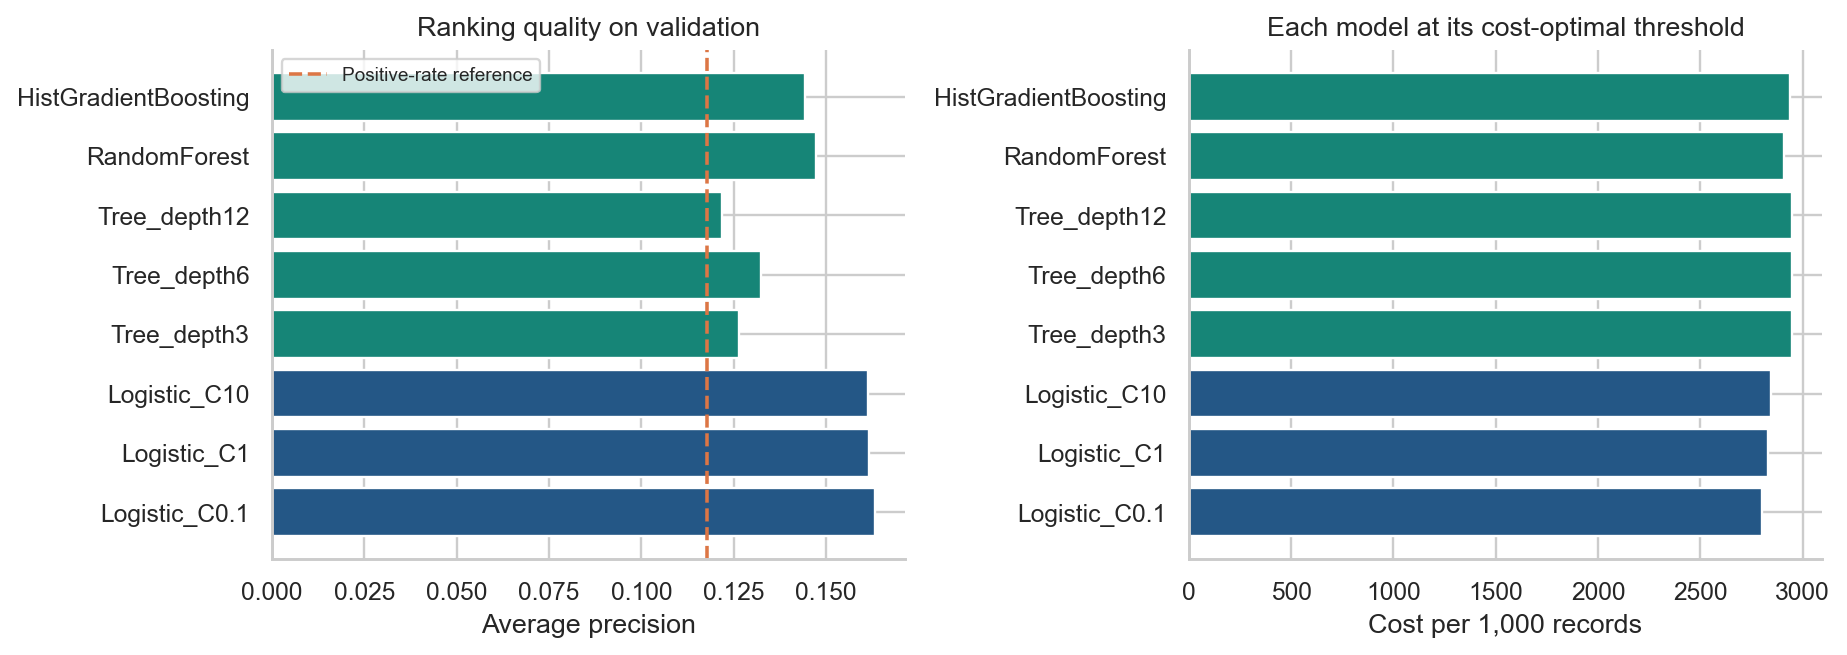

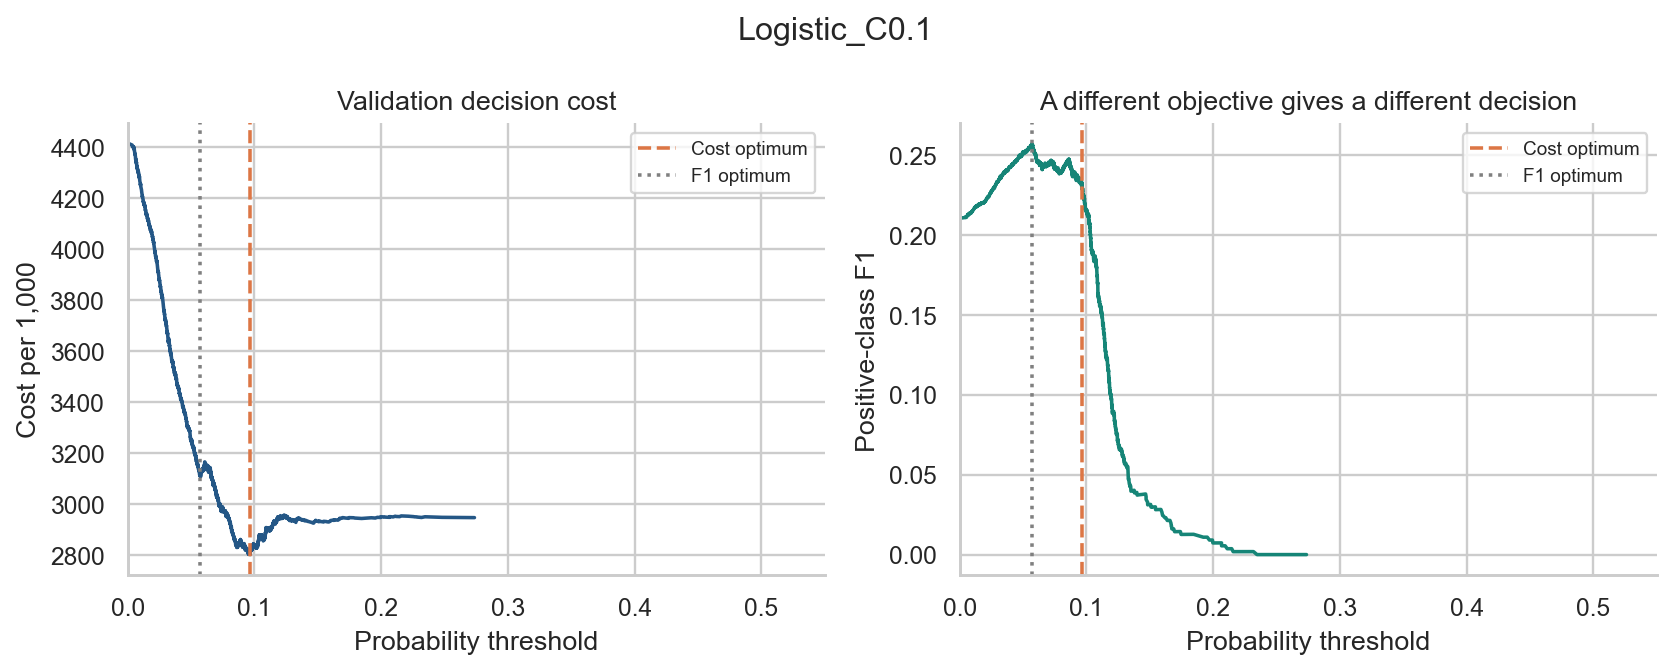

**Logistic_C0.1** minimizes validation cost at the full-precision threshold **0.096576912537320064**. Its validation cost is **2,803.03 per 1,000**, versus **2,947.36** at 0.5. The F1-at-0.5 winner is **Tree_depth12**, while the AP winner is **Logistic_C0.1**. These rankings measure different things. A model can rank some positives ahead of negatives yet predict no positives at 0.5, producing zero positive-class F1.

The selected model's F1-maximizing threshold is **0.056903393163356519**; its validation cost is **3,112.14 per 1,000**. The cost policy instead acts on **17.68%** of validation records. We do not round a threshold before making predictions. Under calibrated probabilities and this exact loss matrix, a positive action has expected loss 5(1-p), and a negative action has loss 25p. Hence the analytic cutoff is 5/(5+25) = 1/6. The empirically selected cutoff need not equal 1/6: the scores are not guaranteed to be calibrated in the later population. The analytic policy is a diagnostic comparison, not a replacement chosen after testing.

In [21]:
display(Image(filename=str(study.figures/'validation_models.png')))
display(Image(filename=str(study.figures/'threshold_tradeoff.png')))
display(Markdown(notes['selection']))
display(Markdown(notes['thresholds']))

## Operational policy comparison

A confusion matrix uses **actual classes in rows, predicted classes in columns**, each ordered `no`, `yes`. Compare the false-negative and false-positive trade-off alongside action volume. The policy cost chart deliberately includes both universal action and the no-model prior-success rule.

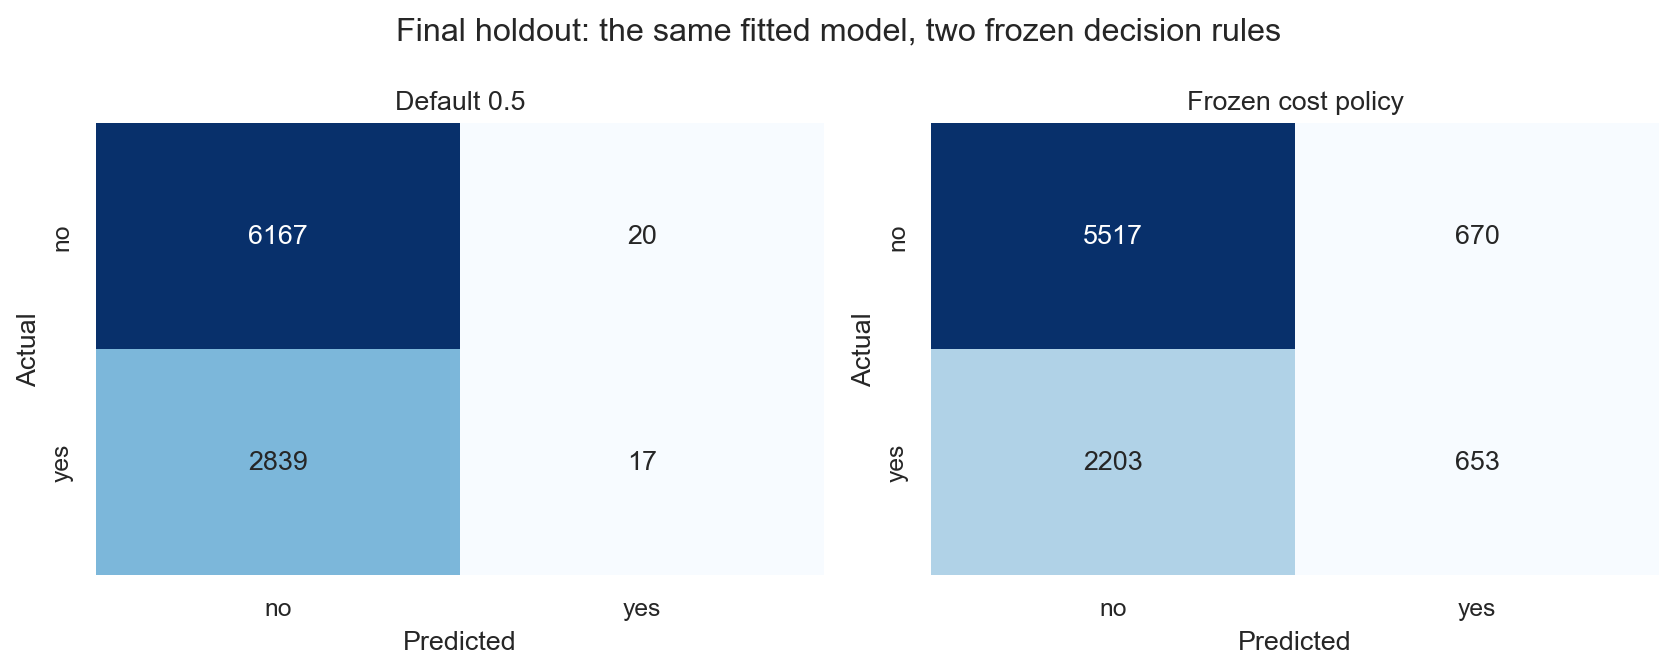

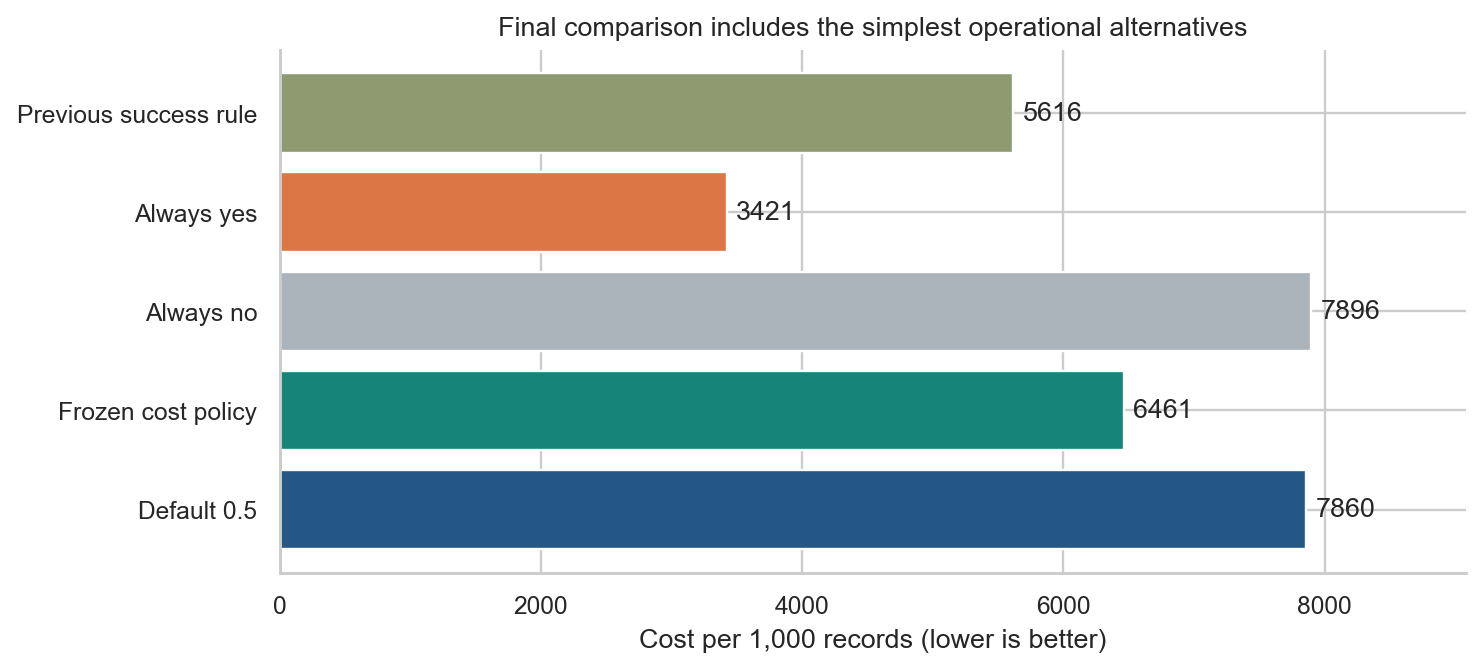

The frozen policy reduces final-period cost from **7,859.67** to **6,460.80 per 1,000**, a **17.80%** reduction relative to 0.5. Recall rises from **0.60%** to **22.86%**, while the action rate rises from **0.41%** to **14.63%**. However, **Always yes** costs **3,420.88 per 1,000** and the previous-success rule costs **5,615.95**. Both simple alternatives outperform the frozen model on this holdout. The learned model therefore does not establish operational superiority, despite beating its default threshold. Always-yes requires action on every record and may violate real capacity limits; no such limit is built into the primary cost objective. All baselines were declared before holdout evaluation. We do not switch the operational policy using this test result.

,policy,cost_per_1000_validation,cost_per_1000_test
0,Default 0.5,2947.356779,7859.670463
1,Frozen cost policy,2803.030303,6460.798408


In [22]:
display(Image(filename=str(study.figures/'test_confusion_matrices.png')))
display(Image(filename=str(study.figures/'test_policy_costs.png')))
display(Markdown(notes['test']))
comparison = study.validation_policies[['policy','cost_per_1000']].merge(
    study.test_results[['policy','cost_per_1000']], on='policy', suffixes=('_validation','_test'))
display(comparison)

## Temporal distribution shift and probability reliability

AP is prevalence-sensitive, so a larger AP in a later period is not directly comparable to an earlier-period AP without class-rate context. Reliability examines the meaning of scores separately from ranking. A better Brier loss than a training-rate constant does not certify calibration across future periods.

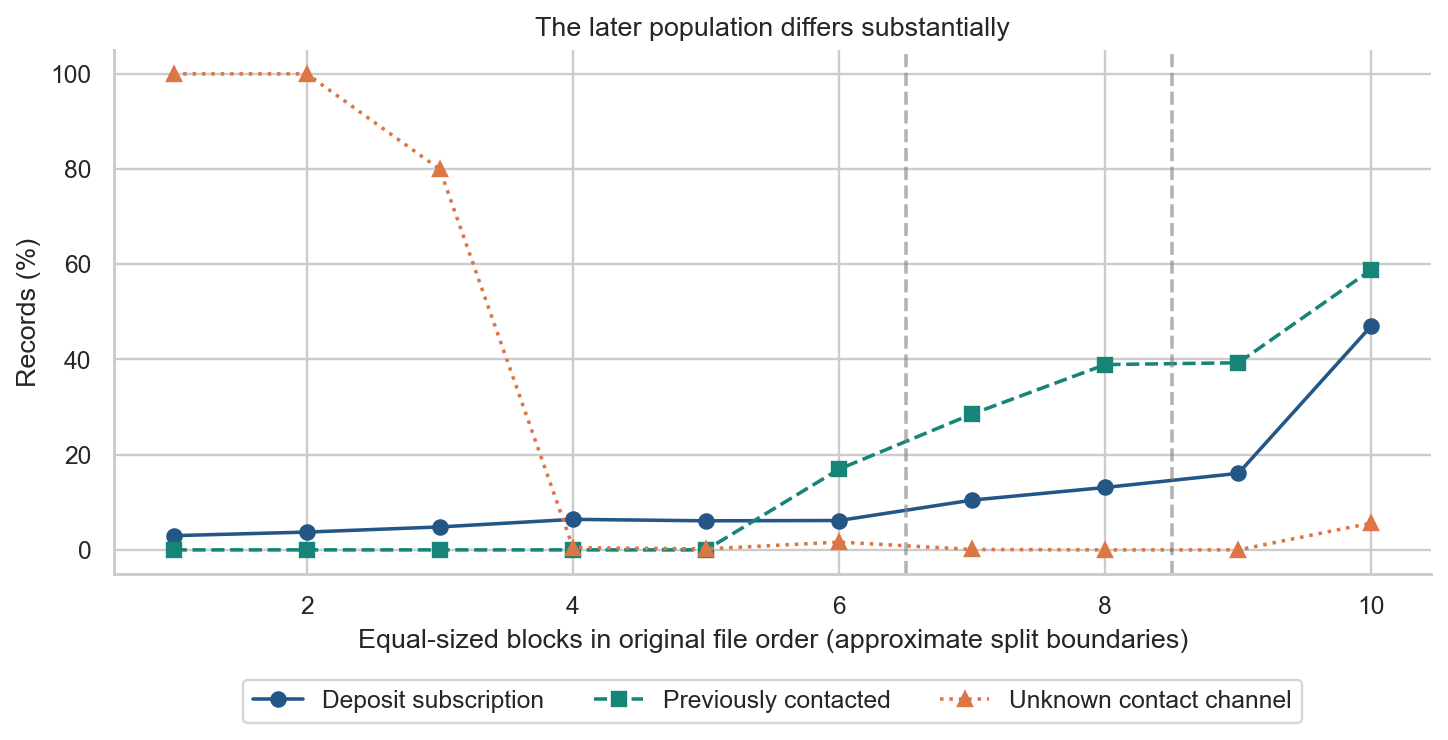

The positive rate rises from **5.04%** in training to **11.79%** in validation and **31.58%** in the final period. Contact-channel availability and prior-contact history also change across ordered blocks. This is evidence of distribution change, not proof of pure label shift. Calendar years and customer IDs are absent, so blocks are file-order windows, not reconstructed months or independent customer cohorts. Row order comes from the source documentation.

,block,start,end_exclusive,rows,positive_rate,unknown_contact_rate,previously_contacted_rate
0,1,0,4522,4522,0.029854,1.000000,0.000000
1,2,4522,9043,4521,0.037381,1.000000,0.000000
2,3,9043,13564,4521,0.048219,0.799381,0.000000
3,4,13564,18085,4521,0.064145,0.004645,0.000000
4,5,18085,22606,4521,0.061048,0.001991,0.000000
5,6,22606,27127,4521,0.061712,0.016368,0.169653
6,7,27127,31648,4521,0.104623,0.000885,0.285556
7,8,31648,36169,4521,0.131166,0.000000,0.389294
8,9,36169,40690,4521,0.160805,0.000000,0.393055
9,10,40690,45211,4521,0.470914,0.056403,0.588808


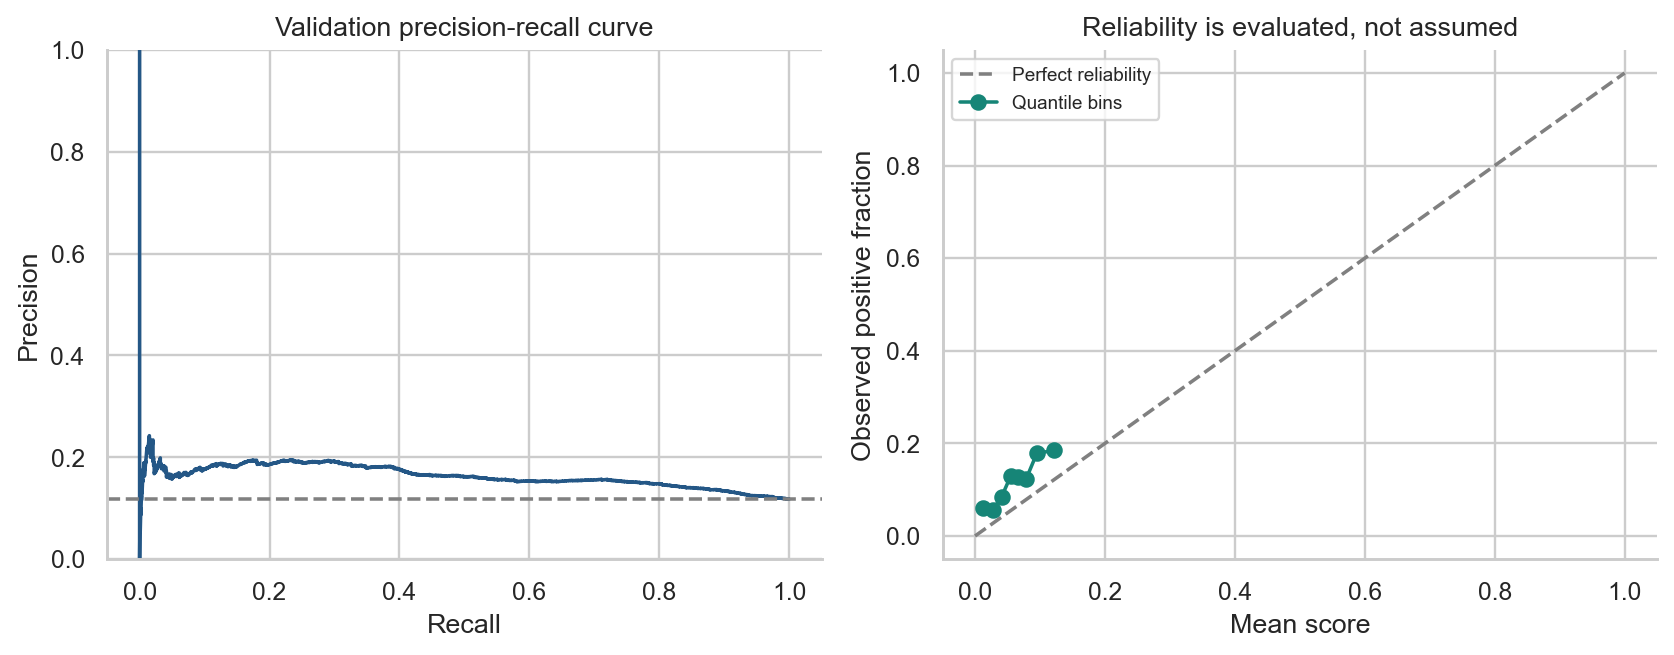

,policy,mean_score,average_precision,roc_auc,brier
0,Logistic_C0.1,0.062173,0.163352,0.620729,0.105375
1,Training-rate constant,0.050394,0.117894,0.500000,0.108551


In [23]:
display(Image(filename=str(study.figures/'temporal_shift.png')))
display(Markdown(notes['shift']))
display(study.drift)
display(Image(filename=str(study.figures/'ranking_and_reliability.png')))
display(study.probability_quality)

## Cost sensitivity, capacity and prevalence scenarios

Changing both costs by a common multiplier preserves the chosen decisions and scales the loss. Changing their ratio can change both model and threshold. A score-based capacity rule can split tied probabilities by row order and therefore need not be equivalent to one deterministic threshold.

The prevalence curves isolate one assumption: class-conditional error rates remain as measured on validation. The observed dataset also changes in feature composition; these curves must not be interpreted as forecasts of the actual final period.

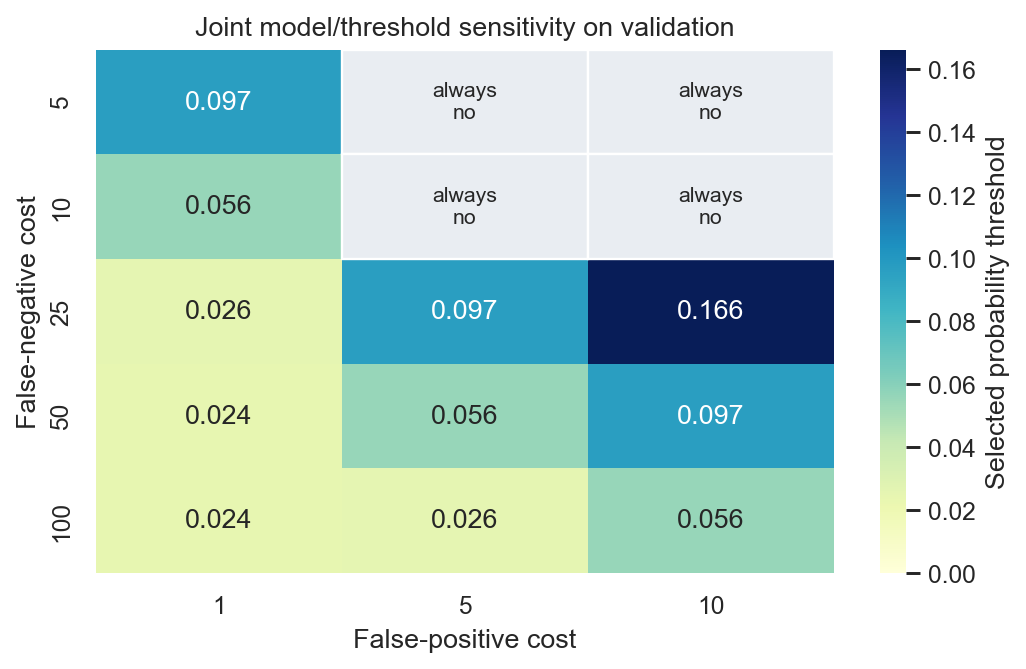

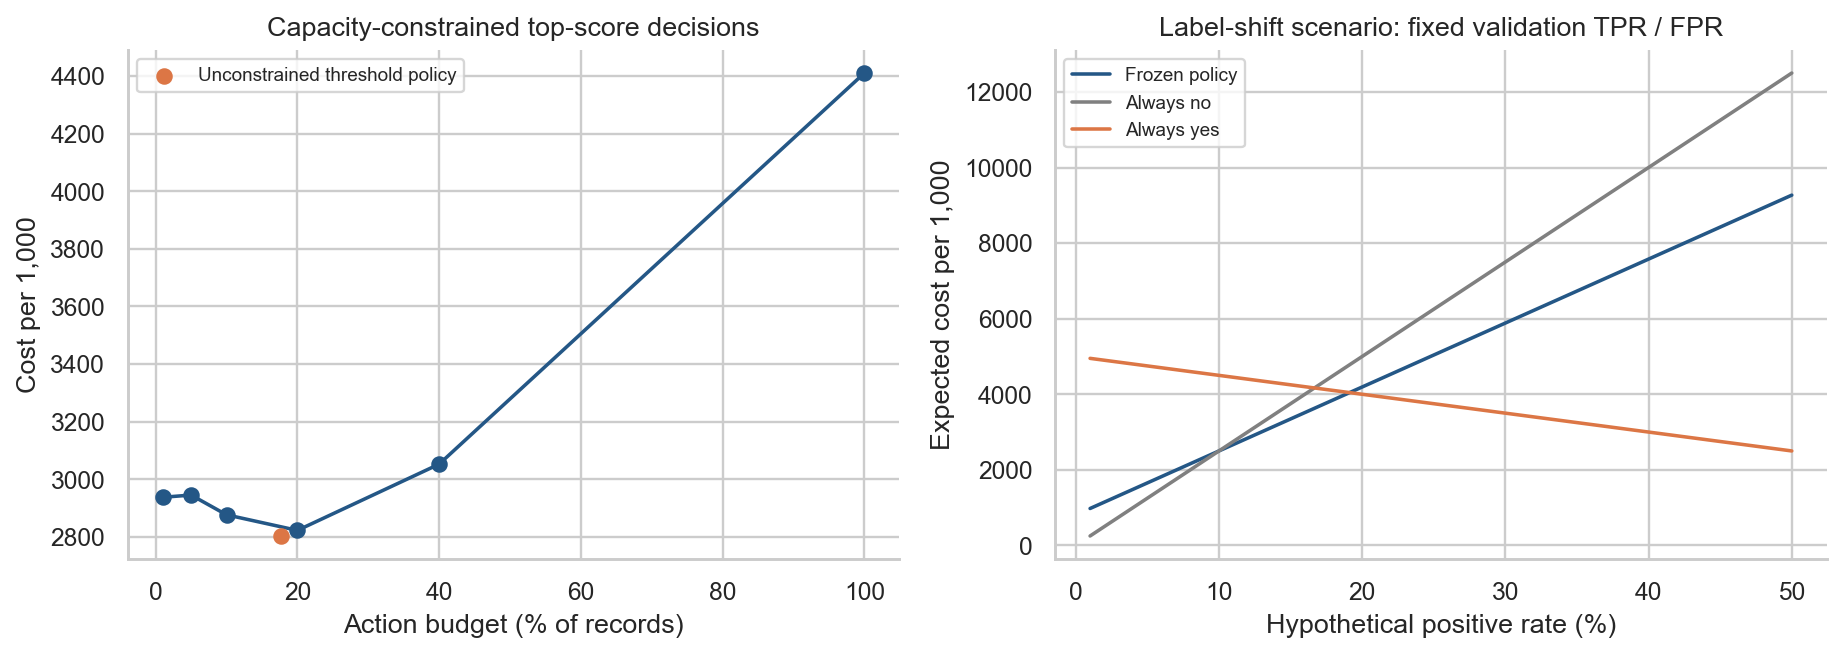

,fp_cost,fn_cost,model,threshold,precision,recall,cost_per_1000
0,1,5,Logistic_C0.1,0.096577,0.193871,0.290807,560.606061
1,1,10,Logistic_C10,0.055593,0.152277,0.784240,769.077638
2,1,25,RandomForest,0.025981,0.118862,0.999062,875.912409
3,1,50,RandomForest,0.024235,0.118313,1.000000,878.566689
4,1,100,RandomForest,0.024235,0.118313,1.000000,878.566689
5,5,5,Logistic_C0.1,inf,0.000000,0.000000,589.471356
6,5,10,Logistic_C0.1,inf,0.000000,0.000000,1178.942712
7,5,25,Logistic_C0.1,0.096577,0.193871,0.290807,2803.030303
8,5,50,Logistic_C10,0.055593,0.152277,0.784240,3845.388188
9,5,100,RandomForest,0.025981,0.118862,0.999062,4376.797169


In [24]:
display(Image(filename=str(study.figures/'cost_sensitivity.png')))
display(Image(filename=str(study.figures/'business_scenarios.png')))
display(study.sensitivity[['fp_cost','fn_cost','model','threshold','precision','recall','cost_per_1000']])

## Earlier chronological stability

The fixed-family audit uses outer training-prefix fractions 35%, 50% and 65%. Each prefix uses its first 80% to fit and last 20% to tune a threshold; the next 10% of the complete file is the outer evaluation window. The last outer window ends at 75%, leaving the final 20% unused. All preprocessing is fitted within each inner training subset, and the tuned threshold stays fixed for its outer window.

The overlapping histories are stress scenarios, not independent folds or a nested search across the full candidate set.

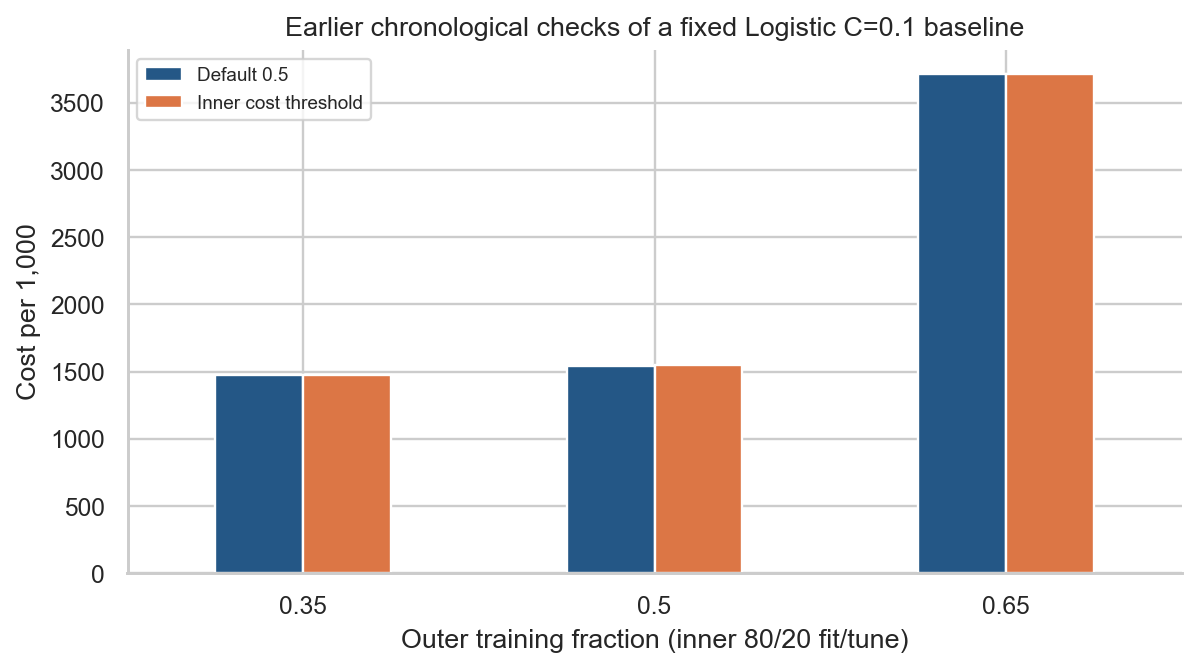

The inner-tuned threshold improves over 0.5 in **0 of 3** earlier outer windows for the predeclared Logistic C=0.1 baseline. Each outer training prefix is split into 80% fitting and 20% threshold tuning, then evaluated on the next 10% of the full file. Every row used by this audit precedes the final 20% holdout. The windows overlap in training history and are not independent replications. This audit tests a fixed family; it is not nested model selection for the entire eight-model search. Threshold improvement is not stable across all earlier periods.

In [25]:
display(Image(filename=str(study.figures/'chronological_stability.png')))
display(Markdown(notes['stability']))

## Predictive interpretation and information availability

Permutation importance measures the decrease in validation AP after shuffling one raw feature. Correlated features can substitute for each other. The three-repeat SD measures shuffle variation, not population uncertainty, and a negative importance is possible. Importance does not identify causal levers or justify changing sensitive client attributes.

The duration audit measures the change in validation metrics when completed-call information is included. This separate audit demonstrates the effect of information availability on the validity of the operational model.

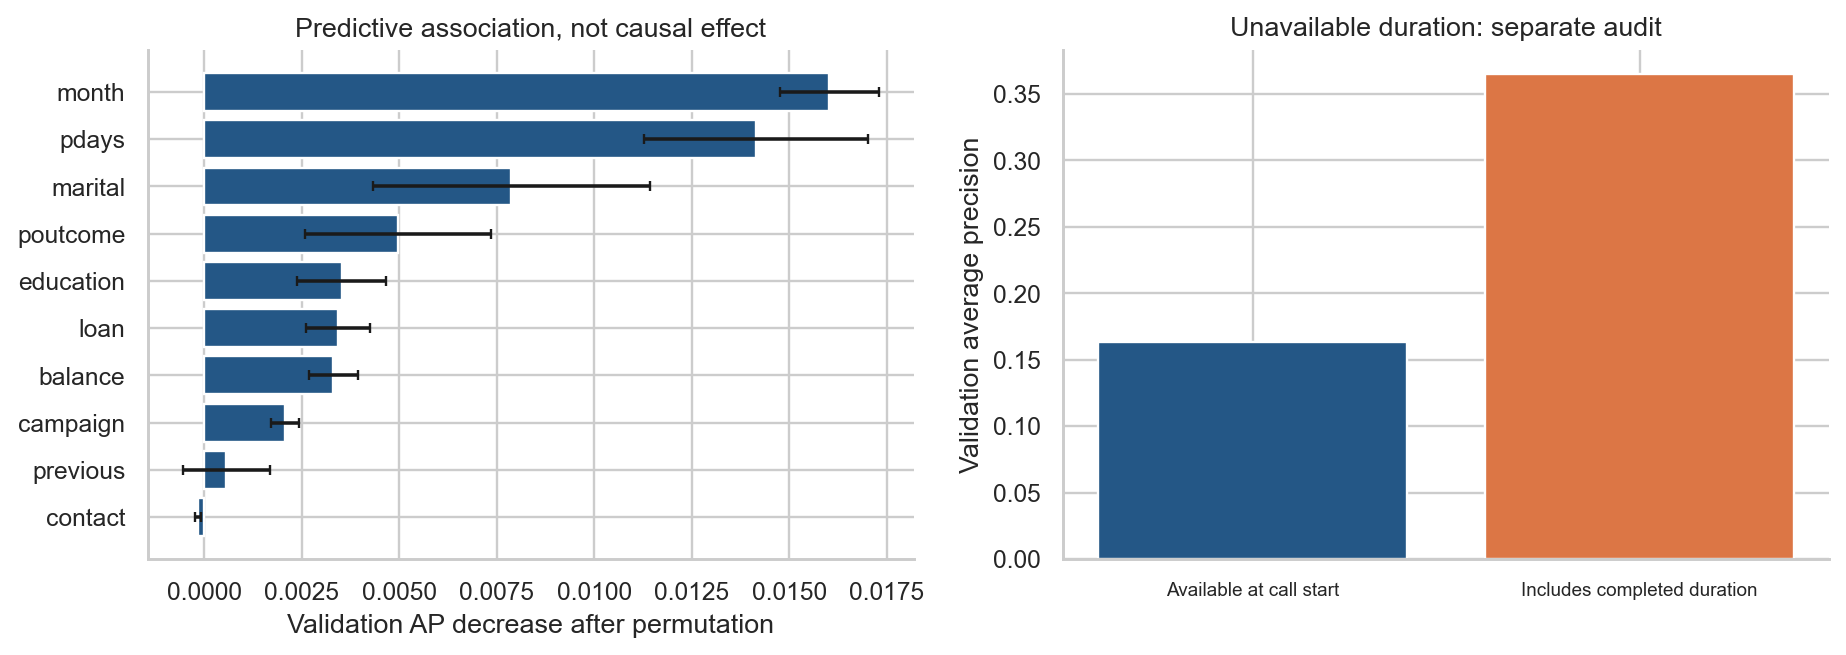

,feature,ap_decrease,repeat_sd
10,month,0.016025,0.001265
12,pdays,0.014142,0.002863
2,marital,0.007878,0.003543
14,poutcome,0.004976,0.002381
3,education,0.003523,0.001151
7,loan,0.003423,0.000819
5,balance,0.003313,0.000631
11,campaign,0.002075,0.000362
13,previous,0.000572,0.001122
8,contact,-0.000154,0.000073


Adding completed-call duration changes validation AP from **0.1634** to **0.3649**, and F1 at 0.5 from **0.0000** to **0.2219**. These values come from a separate training-only refit with the same estimator settings. Duration becomes available after the stated decision time, so this audit model is excluded from selection, inference and the saved operational artifact.

In [26]:
display(Image(filename=str(study.figures/'importance_and_leakage.png')))
display(study.importance)
display(Markdown(notes['leakage']))

## Uncertainty and descriptive subgroup checks

We compare frozen-minus-default loss using a **paired circular moving-block bootstrap** on test records, with 1,000 resamples each for block lengths 50, 200 and 500. Resampling identical record positions for both policies preserves their paired comparison. Neighboring records are kept together within blocks to approximate short-range dependence.

Age bands and contact-channel groups report counts and errors at the frozen threshold. They are descriptive audits, not separate tuning sets or a fairness certification. No individual-level or customer-cluster independence assumption can be verified without identifiers.

In [27]:
display(study.bootstrap)
display(Markdown(notes['uncertainty']))
display(study.subgroups[['feature','group','rows','positives','positive_rate','precision','recall','action_rate','cost_per_1000']])

,delta_per_1000,lower_95,upper_95,repeats,block_size,seed
0,-1398.872056,-1748.424196,-1088.659737,1000,50,42
1,-1398.872056,-2031.460798,-864.190534,1000,200,42
2,-1398.872056,-2222.257547,-662.929891,1000,500,42


A paired circular moving-block bootstrap with blocks of 200 records and 1,000 resamples estimates the frozen-minus-default cost difference as **-1,398.87 per 1,000**, with a descriptive 95% percentile interval **[-2,031.46, -864.19]**. The table also uses block lengths 50 and 500. Pairing keeps the same resampled outcomes for both policies. These intervals are conditional on the fitted model, chosen threshold and observed period; they omit training and policy-selection uncertainty. Circular blocks only approximate local dependence, especially under nonstationary drift, and are not customer-cluster or future-period guarantees.

,feature,group,rows,positives,positive_rate,precision,recall,action_rate,cost_per_1000
0,age_band,"[0, 30)",1713,578,0.337420,0.536131,0.397924,0.250438,5659.661413
1,age_band,"[30, 50)",5047,1404,0.278185,0.490265,0.197293,0.111948,5867.842283
2,age_band,"[50, 120)",2283,874,0.382830,0.443769,0.167048,0.144109,8372.755147
3,contact,cellular,7889,2587,0.327925,0.519247,0.234635,0.148181,6630.751680
4,contact,telephone,899,236,0.262514,0.391304,0.190678,0.127920,5700.778643
5,contact,unknown,255,33,0.129412,0.025641,0.030303,0.152941,3882.352941


## Scoring records with the frozen policy

The retained pipeline accepts the 15 named call-start inputs without target or completed duration. Extra fields are ignored by the feature whitelist, unseen categories are supported, and missing required fields raise an error.

The demonstration below uses five historical records from the evaluated period, with the target and duration removed. These examples verify the scoring interface and do not constitute a new evaluation set. The optional model file created in `artifacts/models/` can be reloaded in a session where the feature-transformer definition above is available; no model file is required before running the notebook.

In [28]:
def predict(frame: pd.DataFrame, model_dir: Path) -> pd.DataFrame:
    """Only load joblib artifacts from a trusted source."""
    model_dir = Path(model_dir)
    policy = json.loads((model_dir / 'policy.json').read_text())
    model = joblib.load(model_dir / 'pipeline.joblib')
    threshold = policy['threshold']
    if threshold == 'infinity':
        threshold = np.inf
    probability = model.predict_proba(frame)[:, 1]
    return pd.DataFrame({'probability_yes': probability,
                         'decision': np.where(probability >= threshold, 'yes', 'no')}, index=frame.index)

In [29]:
example = study.X_test[INPUTS].head(5).copy()
display(example)
scored = predict(example, RUN_DIR/'models')
display(scored)
np.testing.assert_allclose(scored.probability_yes, study.p_test[:len(example)], rtol=1e-12, atol=1e-12)
extra = example.assign(y='yes', duration=999999)
pd.testing.assert_frame_equal(scored, predict(extra, RUN_DIR/'models'))
print('Reloaded predictions match the retained model; target and duration do not affect scoring.')

,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome
36168,35,blue-collar,single,secondary,no,41,yes,no,cellular,11,may,5,-1,0,unknown
36169,40,blue-collar,married,secondary,no,1844,yes,no,cellular,11,may,1,-1,0,unknown
36170,40,blue-collar,married,primary,no,98,yes,no,cellular,11,may,2,343,5,failure
36171,49,blue-collar,divorced,primary,no,24,yes,no,cellular,11,may,1,362,1,success
36172,33,blue-collar,married,secondary,no,358,no,no,cellular,11,may,1,350,1,failure


,probability_yes,decision
36168,0.047420,no
36169,0.036841,no
36170,0.005402,no
36171,0.018677,no
36172,0.008255,no


Reloaded predictions match the retained model; target and duration do not affect scoring.


## Recommendation and limits

The case study does not establish that the learned policy is the best business decision. The simpler alternatives and the chronological instability are substantive results. The loss matrix omits a charge for action on true positives and does not enforce a fixed capacity. Adjusting that objective is a new decision problem requiring new validation, not a justification for optimizing on the examined holdout.

The observed label belongs to contacted customers. Without counterfactual outcomes or randomized action assignment, neither this model nor the rule baselines estimate incremental subscriptions, campaign uplift or ROI. The data also lack full timestamps and customer identifiers, and may encode historical selection and social biases.

In [30]:
display(Markdown(notes['decision']))
display(pd.Series(json.loads((study.report/'environment.json').read_text()), name='run_environment').to_frame())
print('All calculations, figures and local artifacts were rebuilt by this standalone notebook.')

The result supports separating ranking, probability estimation and business decisions. It does not yet justify deployment. Before a prospective pilot, agree on actual action costs, opportunity costs and capacity; evaluate the previous-success rule and a broader contact policy alongside the model; collect fresh labeled periods for recalibration and threshold review. Monitor score and category changes immediately, and response rates, conditional error rates, action rates and realized decision costs after labels arrive. Trigger retraining or policy review using limits set before the next evaluation, then validate on a new future period. A controlled experiment is needed to estimate incremental subscriptions or profit caused by contacting people.

,run_environment
numpy,2.3.5
pandas,2.2.3
scipy,1.16.3
scikit-learn,1.8.0
matplotlib,3.10.8
seaborn,0.13.2
joblib,1.5.2
threadpoolctl,3.8.0
python,3.11.8
platform,macOS-27.2-arm64-arm-64bit


All calculations, figures and local artifacts were rebuilt by this standalone notebook.


## Reproduction and references

All analysis functions, pipelines, threshold searches and plots are defined in this notebook. The executable checks compare exact threshold counts with brute-force predictions, verify capacity ties, confirm final-cost arithmetic and test reloaded predictions. The README documents dependency versions and execution. Minor floating-point differences across operating systems can affect the last digits of a selected threshold; confusion counts and decision costs provide more meaningful comparison points.

- Moro, S., Rita, P., & Cortez, P. (2014). **Bank Marketing** [Dataset]. UCI Machine Learning Repository. [DOI 10.24432/C5K306](https://doi.org/10.24432/C5K306). [Dataset portal](https://archive.ics.uci.edu/dataset/222/bank+marketing). Data license: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). The exact older `bank-full.csv` is used; the original CSV is not modified in the cache.
- scikit-learn: [threshold tuning](https://scikit-learn.org/stable/modules/classification_threshold.html), [calibration](https://scikit-learn.org/stable/modules/calibration.html), [common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html).

The dataset creators do not endorse this project. Data-derived features, predictions and charts are project analysis outputs.